# Análise e Tratamento dos Dados de Churn

Nesta atividade será feita a análise e o tratamento de dados de Churn para preparar o dataset para treinamento de algoritmos de aprendizado de máquina para conseguir identificar quais os clientes mais prováveis de dar churn (abandonar o plano). Será considerado 60 dias de período até o churn.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
%matplotlib inline

# Cores dos gráficos (mesmas dos slides): azul = permanência (0), laranja = churn (1)
CORES = ['#3e7fb5', '#ed7d31']

In [2]:
# Importando os dados

df_churn = pd.read_excel("base_churn_5000_VF2_aluno.xlsx")

print("Primeiras linhas do dataset")
df_churn.head()

Primeiras linhas do dataset


,id_cliente,data_aquisicao_cliente,mensalidade_rs,data_chamado,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,data_ocorrencia_churn
0,C0001,21/04/2024,67.96,"09/09/2026, 15/08/2026",0.0,Bienal,Boleto,0,0,NaN
1,C0002,21/02/2025,65.95,NaN,0.0,Mensal,Cartão,0,0,NaN
2,C0003,21/03/2025,100.88,28/08/2026,1.0,Anual,Boleto,1,1,NaN
3,C0004,21/03/2025,94.80,"06/08/2026, 28/07/2026",2.0,Mensal,Cartão,0,1,NaN
4,C0005,21/02/2022,53.68,05/07/2026,2.0,Anual,Pix,0,0,NaN


### Exploração dos dados (não tratados)

In [3]:
print("Informações gerais da base de dados:")
df_churn.info()

Informações gerais da base de dados:
<class 'pandas.DataFrame'>
RangeIndex: 5020 entries, 0 to 5019
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_cliente              5020 non-null   str    
 1   data_aquisicao_cliente  5020 non-null   str    
 2   mensalidade_rs          4900 non-null   float64
 3   data_chamado            3967 non-null   str    
 4   atrasos_6m              4985 non-null   float64
 5   tipo_contrato           4994 non-null   str    
 6   forma_pagamento         5000 non-null   str    
 7   fibra_optica            5020 non-null   int64  
 8   debito_automatico       5020 non-null   int64  
 9   data_ocorrencia_churn   1789 non-null   str    
dtypes: float64(2), int64(2), str(6)
memory usage: 392.3 KB


Observa-se que há colunas com dados faltantes.

In [4]:
print("Estatísticas descritivas das colunas numéricas:")
df_churn.describe()

Estatísticas descritivas das colunas numéricas:


,mensalidade_rs,atrasos_6m,fibra_optica,debito_automatico
count,4900.000000,4985.000000,5020.000000,5020.000000
mean,91.236551,1.204213,0.568127,0.396215
std,283.898952,4.035609,0.495386,0.489159
min,-85.000000,0.000000,0.000000,0.000000
25%,66.980000,0.000000,0.000000,0.000000
50%,85.915000,1.000000,1.000000,0.000000
75%,98.482500,2.000000,1.000000,1.000000
max,9999.000000,99.000000,1.000000,1.000000


Os valores mínimo e máximo das mensalidades estão fora do esperado (há valores negativos e valores muito altos) e precisam ser tratados.

In [5]:
print("Estatísticas descritivas das colunas de texto:")
df_churn.describe(exclude='number')

Estatísticas descritivas das colunas de texto:


,id_cliente,data_aquisicao_cliente,data_chamado,tipo_contrato,forma_pagamento,data_ocorrencia_churn
count,5020,5020,3967,4994,5000,1789
unique,5000,86,2407,6,6,61
top,C0497,21/07/2025,10/07/2026,Mensal,Boleto,17/10/2026
freq,2,171,24,2726,1953,43


Podemos ver que há clientes duplicados, pois a coluna de identificação (id_cliente) não tem todos os valores únicos.

#### Gráficos da base bruta

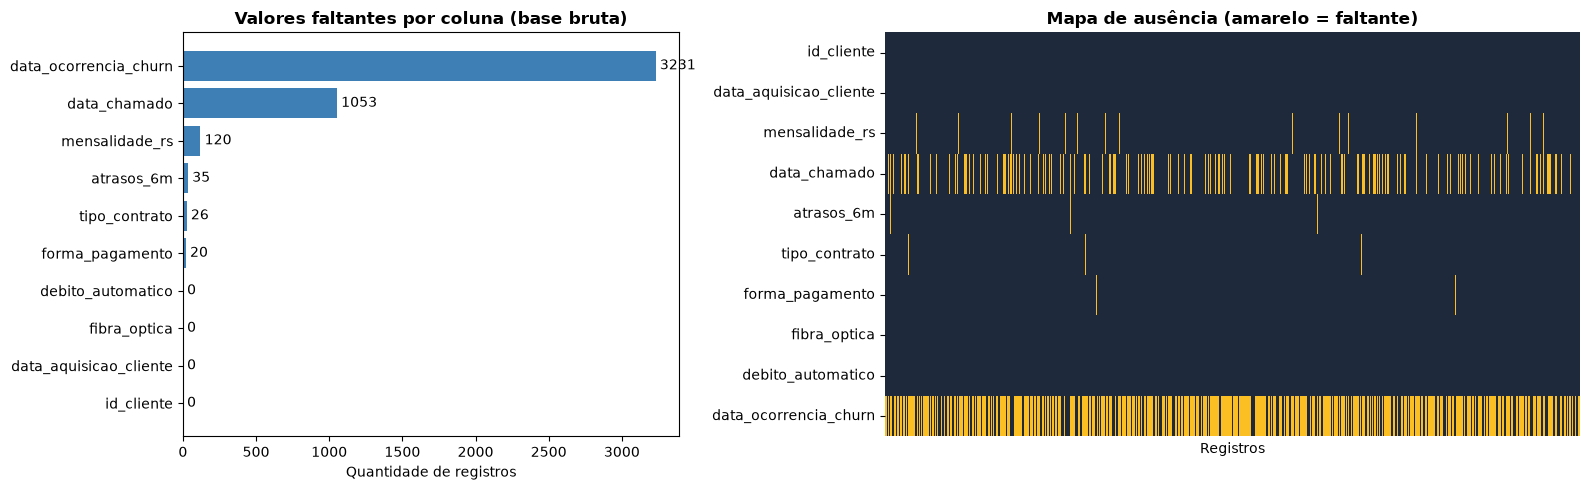

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 1.4]})

# Gráfico de barras: quantidade de faltantes por coluna
faltantes = df_churn.isna().sum().sort_values()
barras = axes[0].barh(faltantes.index, faltantes.values, color='#3e7fb5')
axes[0].bar_label(barras, padding=3)
axes[0].set_title('Valores faltantes por coluna (base bruta)', fontweight='bold')
axes[0].set_xlabel('Quantidade de registros')

# Mapa de calor da ausência: cada linha horizontal clara é um valor faltante
sns.heatmap(df_churn.isna().T, cbar=False, cmap=['#1e293b', '#fbbf24'], ax=axes[1], xticklabels=False)
axes[1].set_title('Mapa de ausência (amarelo = faltante)', fontweight='bold')
axes[1].set_xlabel('Registros')

plt.tight_layout()
plt.show()

data_chamado e data_ocorrencia_churn têm muitos vazios, mas isso é esperado: vazio significa que o cliente não abriu chamado ou não cancelou. Nas demais colunas os faltantes aparecem espalhados, sem bloco concentrado.

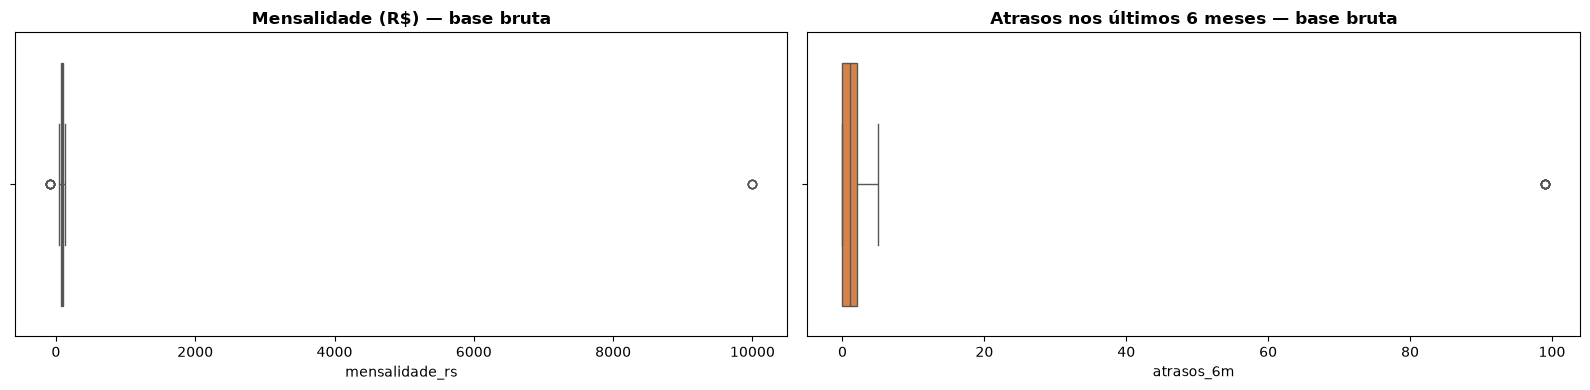

Mensalidades fora de [10, 500]: [np.float64(-85.0), np.float64(9999.0)]
Atrasos fora de [0, 6]: [np.float64(99.0)]


In [7]:
# Boxplots das colunas numéricas brutas: os pontos isolados são os valores discrepantes
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.boxplot(ax=axes[0], x=df_churn['mensalidade_rs'], color='#ed7d31')
axes[0].set_title('Mensalidade (R$) — base bruta', fontweight='bold')
sns.boxplot(ax=axes[1], x=df_churn['atrasos_6m'], color='#ed7d31')
axes[1].set_title('Atrasos nos últimos 6 meses — base bruta', fontweight='bold')
plt.tight_layout()
plt.show()

print("Mensalidades fora de [10, 500]:", sorted(df_churn.loc[~df_churn['mensalidade_rs'].between(10, 500) & df_churn['mensalidade_rs'].notna(), 'mensalidade_rs'].unique()))
print("Atrasos fora de [0, 6]:", sorted(df_churn.loc[~df_churn['atrasos_6m'].between(0, 6) & df_churn['atrasos_6m'].notna(), 'atrasos_6m'].unique()))

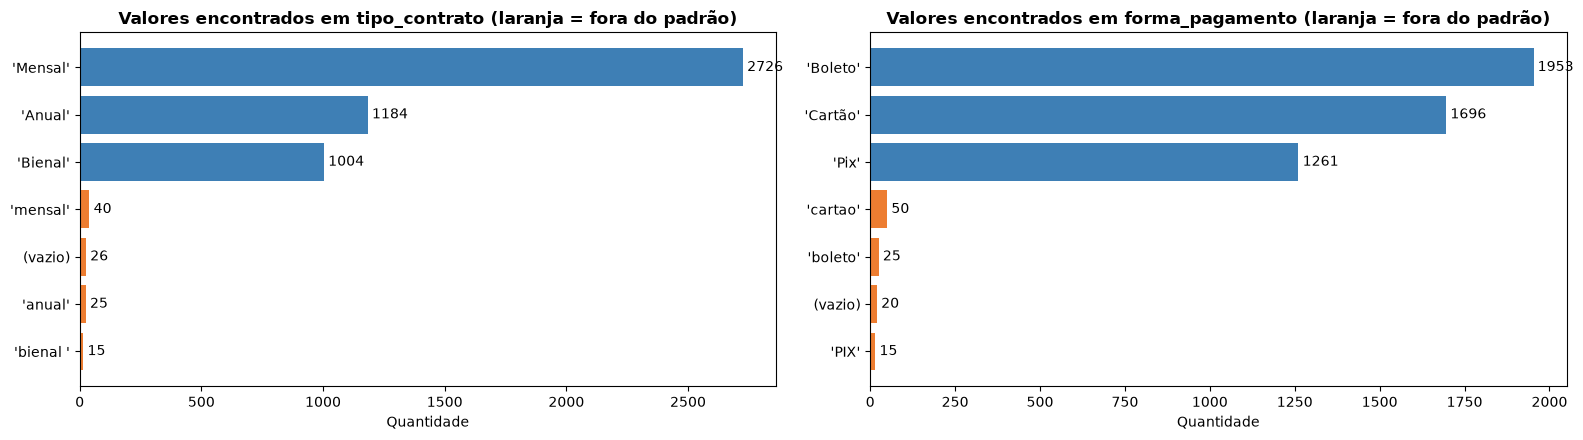

In [8]:
# Gráfico de barras dos valores de texto exatamente como estão escritos na base
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, coluna in zip(axes, ['tipo_contrato', 'forma_pagamento']):
    contagem = df_churn[coluna].map(lambda v: '(vazio)' if pd.isna(v) else repr(v)).value_counts()
    cores = ['#3e7fb5' if v.strip("'") in ['Mensal', 'Anual', 'Bienal', 'Boleto', 'Cartão', 'Pix'] else '#ed7d31' for v in contagem.index]
    ax.barh(contagem.index, contagem.values, color=cores)
    ax.bar_label(ax.containers[0], padding=3)
    ax.invert_yaxis()
    ax.set_title(f'Valores encontrados em {coluna} (laranja = fora do padrão)', fontweight='bold')
    ax.set_xlabel('Quantidade')
plt.tight_layout()
plt.show()

### Criação da visão de dados

Antes de separar treino e teste, montamos a base com uma linha por cliente (chave id_cliente + data_corte), com os atributos conhecidos até a data de corte e o alvo (churn). Nessa etapa não calculamos nenhuma estatística para preencher ou transformar os dados.

In [9]:
# Observando dados duplicados

duplicadas = df_churn[df_churn.duplicated(subset=['id_cliente'], keep=False)]
print(f"Unicidade antes: {df_churn['id_cliente'].nunique() / len(df_churn):.2%}")
display(duplicadas.sort_values('id_cliente'))

Unicidade antes: 99.60%


,id_cliente,data_aquisicao_cliente,mensalidade_rs,data_chamado,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,data_ocorrencia_churn
496,C0497,21/07/2024,110.68,02/08/2026,2.0,Mensal,Cartão,1,0,04/10/2026
5004,C0497,21/07/2024,110.68,02/08/2026,2.0,Mensal,Cartão,1,0,04/10/2026
806,C0807,21/12/2025,77.40,"09/09/2026, 05/09/2026, 30/06/2026",2.0,Anual,Cartão,0,0,NaN
5003,C0807,21/12/2025,77.40,"09/09/2026, 05/09/2026, 30/06/2026",2.0,Anual,Cartão,0,0,NaN
856,C0857,21/01/2025,104.26,19/08/2026,2.0,Bienal,Boleto,1,0,NaN
5013,C0857,21/01/2025,104.26,19/08/2026,2.0,Bienal,Boleto,1,0,NaN
1113,C1114,21/06/2024,52.14,NaN,0.0,Mensal,Cartão,0,0,NaN
5011,C1114,21/06/2024,52.14,NaN,0.0,Mensal,Cartão,0,0,NaN
1150,C1151,21/06/2024,93.11,"15/08/2026, 06/08/2026, 30/07/2026",0.0,NaN,Cartão,1,0,29/09/2026
5008,C1151,21/06/2024,93.11,"15/08/2026, 06/08/2026, 30/07/2026",0.0,NaN,Cartão,1,0,29/09/2026


Como as linhas duplicadas são idênticas e não têm nenhuma informação a mais que precise ser preservada, podemos eliminar essas linhas. Isso precisa ser feito antes da divisão para o mesmo cliente não cair no treino e no teste ao mesmo tempo.

In [10]:
# Eliminando dados duplicados e refazendo o índice
df_churn = df_churn.drop_duplicates(subset=['id_cliente'], keep='first').reset_index(drop=True)
print(f"Unicidade depois: {df_churn['id_cliente'].nunique() / len(df_churn):.2%}")

Unicidade depois: 100.00%


In [11]:
# Convertendo as colunas de datas para datetime
for coluna in ['data_aquisicao_cliente', 'data_ocorrencia_churn']:
    datas = pd.to_datetime(df_churn[coluna], format='%d/%m/%Y', errors='coerce')
    falhas = df_churn[coluna].notna() & datas.isna()
    if falhas.any():
        print(f"{coluna}: valores fora do formato dd/mm/aaaa -> {df_churn.loc[falhas, coluna].unique()}")
        # Tenta ler os valores em outro formato antes de considerar como faltante
        datas[falhas] = pd.to_datetime(df_churn.loc[falhas, coluna].astype(str), format='mixed', dayfirst=True, errors='coerce')
        print(f"{coluna}: continuam inválidos -> {(df_churn[coluna].notna() & datas.isna()).sum()}")
    df_churn[coluna] = datas

data_aquisicao_cliente: valores fora do formato dd/mm/aaaa -> <StringArray>
['2024-08-21', '2026-06-21', '2022-09-21', '2021-12-21', '2024-12-21',
 '2026-04-21', '2023-06-21', '2026-08-21', '2023-08-21', '2025-03-21',
 '2023-01-21', '2025-07-21', '2021-09-21', '2025-06-21']
Length: 14, dtype: str
data_aquisicao_cliente: continuam inválidos -> 0


#### Tratando e normalizando as colunas de texto

In [12]:
display(df_churn['forma_pagamento'].value_counts(dropna=False))

forma_pagamento
Boleto    1943
Cartão    1689
Pix       1258
cartao      50
boleto      25
NaN         20
PIX         15
Name: count, dtype: int64

In [13]:
df_churn['forma_pagamento'] = df_churn['forma_pagamento'].str.strip().str.title()
df_churn['forma_pagamento'] = df_churn['forma_pagamento'].replace({'Cartao':'Cartão'})

# Os valores faltantes são preenchidos depois da divisão, com a moda do treino
display(df_churn['forma_pagamento'].value_counts(dropna=False))

forma_pagamento
Boleto    1968
Cartão    1739
Pix       1273
NaN         20
Name: count, dtype: int64

In [14]:
display(df_churn['tipo_contrato'].value_counts(dropna=False))

tipo_contrato
Mensal     2717
Anual      1176
Bienal     1002
mensal       40
anual        25
NaN          25
bienal       15
Name: count, dtype: int64

In [15]:
# .str.strip() remove espaços sobrando (ex.: 'bienal ')
df_churn['tipo_contrato'] = df_churn['tipo_contrato'].str.strip().str.title()

# Os valores faltantes são preenchidos depois da divisão, com a moda do treino
display(df_churn['tipo_contrato'].value_counts(dropna=False))

tipo_contrato
Mensal    2757
Anual     1201
Bienal    1017
NaN         25
Name: count, dtype: int64

#### Data de corte e definição do churn

A data de corte é a data de referência da "fotografia" dos clientes. Os atributos só podem usar informações até essa data, e o churn é observado nos 60 dias seguintes.

In [16]:
# Encontrando data limite do dataset
ultima_data_disponivel = max(df_churn['data_aquisicao_cliente'].max(), df_churn['data_ocorrencia_churn'].max())
print(f"Última data disponível: {ultima_data_disponivel}")

# Obtendo a data de referência (data de corte)
data_referencia = ultima_data_disponivel - pd.Timedelta(days=60)
fim_janela = data_referencia + pd.Timedelta(days=60)

# Salva a data de corte no dataframe
df_churn['data_corte'] = data_referencia

print(f"Data de referência (Fotografia): {data_referencia}")
print(f"Fim da janela de observação do churn: {fim_janela}")

Última data disponível: 2026-11-20 00:00:00
Data de referência (Fotografia): 2026-09-21 00:00:00
Fim da janela de observação do churn: 2026-11-20 00:00:00


In [17]:
# Mantém apenas clientes adquiridos antes/na data de referência
# E que não tinham cancelado antes da data de referência
df_modelagem = df_churn[
    (df_churn['data_aquisicao_cliente'] <= data_referencia) &
    (df_churn['data_ocorrencia_churn'].isna() | (df_churn['data_ocorrencia_churn'] > data_referencia))
].copy().reset_index(drop=True)

print(f"Total de registros originais: {len(df_churn)}")
print(f"Clientes ativos e elegíveis na data de referência: {len(df_modelagem)}")

Total de registros originais: 5000
Clientes ativos e elegíveis na data de referência: 4990


In [18]:
# Adiciona a coluna de churn (1 = cancelou em até 60 dias, 0 = reteve)
df_modelagem['churn'] = df_modelagem['data_ocorrencia_churn'].between(
    data_referencia,
    fim_janela,
    inclusive='right'
).astype(int)

# Verificação de consistência e prevalência
print("Distribuição das classes de Churn:")
print(df_modelagem['churn'].value_counts())
print(f"\nPrevalência de churn na janela: {df_modelagem['churn'].mean():.2%}")

Distribuição das classes de Churn:
churn
0    3218
1    1772
Name: count, dtype: int64

Prevalência de churn na janela: 35.51%


#### Tempo do cliente e quantidade de chamados

O tempo ativo é calculado até a data de referência para todos os clientes. Ele não pode usar a data do churn, pois isso seria usar o próprio alvo como atributo. Da mesma forma, só contamos os chamados abertos até a data de referência; chamados depois dela são informação do futuro. Chamados com data anterior à aquisição do cliente (como os de 05/01/2019) são inconsistentes e também não entram.

In [19]:
# Calculando o tempo ativo em dias até a data de referência
df_modelagem['tempo_ativo_dias'] = (data_referencia - df_modelagem['data_aquisicao_cliente']).dt.days

In [20]:
# Adiciona uma coluna com a quantidade de chamados entre a aquisição e a data de referência
# (chamados antes da aquisição do cliente, como os de 05/01/2019, são inconsistentes e não entram)
def contar_chamados(linha):
    if pd.isna(linha['data_chamado']):
        return 0  # quem não tem chamados fica com 0
    datas = pd.to_datetime(pd.Series(str(linha['data_chamado']).split(',')).str.strip(), format='%d/%m/%Y', errors='coerce')
    return int(datas.between(linha['data_aquisicao_cliente'], data_referencia).sum())

df_modelagem['qtd_chamados'] = df_modelagem.apply(contar_chamados, axis=1)

total_chamados = df_modelagem['data_chamado'].dropna().astype(str).str.split(',').str.len().sum()
print(f"Chamados considerados: {df_modelagem['qtd_chamados'].sum()} de {total_chamados}")
print(f"Chamados descartados (inconsistentes): {total_chamados - df_modelagem['qtd_chamados'].sum()}")

Chamados considerados: 8514 de 8566
Chamados descartados (inconsistentes): 52


In [21]:
# Mantém apenas a chave, os atributos e o alvo no DataFrame finalizado
colunas = ['id_cliente', 'data_corte', 'tempo_ativo_dias', 'mensalidade_rs', 'qtd_chamados', 'atrasos_6m',
           'tipo_contrato', 'forma_pagamento', 'fibra_optica', 'debito_automatico', 'churn']

# Seleciona as colunas de df_modelagem e salva em df_final
df_final = df_modelagem[colunas].copy()
display(df_final.head())

,id_cliente,data_corte,tempo_ativo_dias,mensalidade_rs,qtd_chamados,atrasos_6m,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico,churn
0,C0001,2026-09-21,883,67.96,2,0.0,Bienal,Boleto,0,0,0
1,C0002,2026-09-21,577,65.95,0,0.0,Mensal,Cartão,0,0,0
2,C0003,2026-09-21,549,100.88,1,1.0,Anual,Boleto,1,1,0
3,C0004,2026-09-21,549,94.80,2,2.0,Mensal,Cartão,0,1,0
4,C0005,2026-09-21,1673,53.68,1,2.0,Anual,Pix,0,0,0


### Divisão em treino (70%) e teste (30%)

A divisão é feita logo depois da criação da visão de dados, antes da análise de qualidade, do preenchimento, da EDA e das transformações. A estratificação mantém a mesma proporção de churn nos dois conjuntos. A partir daqui, tudo que for calculado (moda, KNN, média e desvio) é aprendido só no treino e o teste apenas recebe a transformação.

In [22]:
# Use df_final em vez de df_churn
treino, teste = train_test_split(df_final, test_size=0.30, stratify=df_final['churn'], random_state=42)
treino = treino.reset_index(drop=True)
teste = teste.reset_index(drop=True)

print(f"Treino: {len(treino)} linhas | churn = {treino['churn'].sum()} | não churn = {(treino['churn'] == 0).sum()} | prevalência = {treino['churn'].mean():.2%}")
print(f"Teste:  {len(teste)} linhas | churn = {teste['churn'].sum()} | não churn = {(teste['churn'] == 0).sum()} | prevalência = {teste['churn'].mean():.2%}")

Treino: 3493 linhas | churn = 1240 | não churn = 2253 | prevalência = 35.50%
Teste:  1497 linhas | churn = 532 | não churn = 965 | prevalência = 35.54%


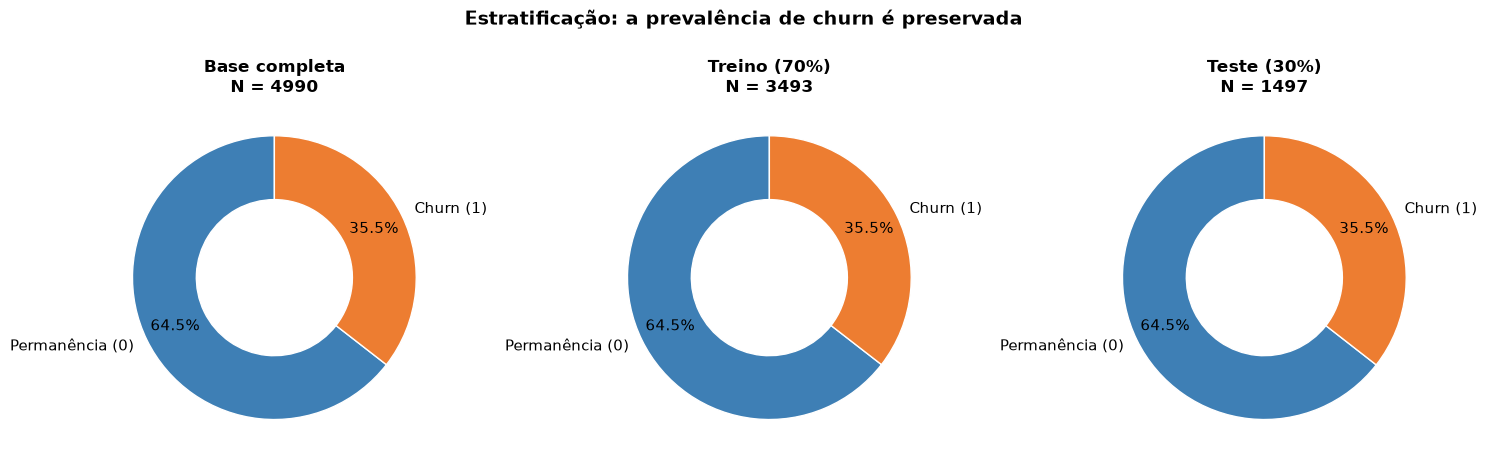

In [23]:
# Gráficos de rosca: proporção de churn em cada conjunto
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (nome, base) in zip(axes, [('Base completa', df_final), ('Treino (70%)', treino), ('Teste (30%)', teste)]):
    contagem = base['churn'].value_counts().sort_index()
    ax.pie(contagem, labels=['Permanência (0)', 'Churn (1)'], colors=CORES, autopct='%1.1f%%', startangle=90,
           wedgeprops={'width': 0.45, 'edgecolor': 'white'}, pctdistance=0.78, textprops={'fontsize': 11})
    ax.set_title(f'{nome}\nN = {len(base)}', fontweight='bold')
plt.suptitle('Estratificação: a prevalência de churn é preservada', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Qualidade dos dados (treino)

#### Inventário de atributos

In [24]:
inventario = pd.DataFrame([
    ['tempo_ativo_dias',  'Numérica',     '[0, 120] meses (0 a 3650 dias)', 'Sim',          'Não pode conter valores negativos'],
    ['mensalidade_rs',    'Numérica',     '[R$ 10.00, R$ 500.00]',          'Não (tem NA)', 'Ausência tratada na auditoria'],
    ['qtd_chamados',      'Numérica',     '[0, 50] chamados',               'Sim',          'Contagem discreta não negativa'],
    ['atrasos_6m',        'Numérica',     '[0, 6] parcelas',                'Sim',          'Inteiro entre 0 e 6'],
    ['tipo_contrato',     'Categórica',   '{Mensal, Anual, Bienal}',        'Sim',          'Requer padronização de caixa'],
    ['forma_pagamento',   'Categórica',   '{Boleto, Cartão, Pix}',          'Sim',          'Requer remoção de acentos'],
    ['fibra_optica',      'Binária',      '{0, 1}',                         'Sim',          'Somente 0 ou 1'],
    ['debito_automatico', 'Binária',      '{0, 1}',                         'Sim',          'Somente 0 ou 1'],
    ['churn',             'Alvo Binário', '{0, 1}',                         'Sim',          'Sem ausência; definido pós-corte'],
], columns=['Atributo', 'Tipo Esperado', 'Faixa Aceita / Domínio', 'Obrigatório', 'Comportamento Esperado'])
inventario

,Atributo,Tipo Esperado,Faixa Aceita / Domínio,Obrigatório,Comportamento Esperado
0,tempo_ativo_dias,Numérica,"[0, 120] meses (0 a 3650 dias)",Sim,Não pode conter valores negativos
1,mensalidade_rs,Numérica,"[R$ 10.00, R$ 500.00]",Não (tem NA),Ausência tratada na auditoria
2,qtd_chamados,Numérica,"[0, 50] chamados",Sim,Contagem discreta não negativa
3,atrasos_6m,Numérica,"[0, 6] parcelas",Sim,Inteiro entre 0 e 6
4,tipo_contrato,Categórica,"{Mensal, Anual, Bienal}",Sim,Requer padronização de caixa
5,forma_pagamento,Categórica,"{Boleto, Cartão, Pix}",Sim,Requer remoção de acentos
6,fibra_optica,Binária,"{0, 1}",Sim,Somente 0 ou 1
7,debito_automatico,Binária,"{0, 1}",Sim,Somente 0 ou 1
8,churn,Alvo Binário,"{0, 1}",Sim,Sem ausência; definido pós-corte


In [25]:
# Regras do inventário
faixas = {'tempo_ativo_dias': (0, 3650), 'mensalidade_rs': (10, 500), 'qtd_chamados': (0, 50), 'atrasos_6m': (0, 6)}
dominios = {'tipo_contrato': ['Mensal', 'Anual', 'Bienal'], 'forma_pagamento': ['Boleto', 'Cartão', 'Pix']}
binarias = ['fibra_optica', 'debito_automatico', 'churn']
atributos_auditoria = list(faixas) + list(dominios) + binarias

def fora_do_inventario(base):
    # Marca os valores preenchidos que estão fora da faixa ou do domínio (faltantes contam na completude)
    fora = pd.DataFrame(index=base.index)
    for coluna, (minimo, maximo) in faixas.items():
        fora[coluna] = base[coluna].notna() & ~base[coluna].between(minimo, maximo)
    fora['atrasos_6m'] = fora['atrasos_6m'] | (base['atrasos_6m'].notna() & (base['atrasos_6m'] % 1 != 0))
    for coluna, dominio in dominios.items():
        fora[coluna] = base[coluna].notna() & ~base[coluna].isin(dominio)
    for coluna in binarias:
        fora[coluna] = base[coluna].notna() & ~base[coluna].isin([0, 1])
    return fora

def dimensoes_qualidade(base):
    fora = fora_do_inventario(base)
    resultado = pd.DataFrame({
        'Dimensão': ['Completude', 'Validade', 'Consistência', 'Unicidade'],
        'Regra': ['Registro sem valores faltantes',
                  'Valores dentro da faixa/domínio do inventário',
                  'Data de aquisição não posterior à data de referência',
                  'Sem repetição de id_cliente + data_corte'],
        'Conformidade': [
            (~base[atributos_auditoria].isna().any(axis=1)).mean(),
            (~fora.any(axis=1)).mean(),
            (base['tempo_ativo_dias'].isna() | (base['tempo_ativo_dias'] >= 0)).mean(),
            (~base.duplicated(subset=['id_cliente', 'data_corte'])).mean()]})
    display(resultado.assign(Conformidade=resultado['Conformidade'].map('{:.2%}'.format)))
    detalhes = pd.DataFrame({'Faltantes': base[atributos_auditoria].isna().sum(), 'Fora do inventário': fora.sum()})
    display(detalhes[detalhes.sum(axis=1) > 0])
    return resultado

def grafico_qualidade(resultado, titulo):
    # Mesmo formato do gráfico da Aula 2 (Diagnóstico das 4 Dimensões de Qualidade)
    valores = resultado['Conformidade'] * 100
    rotulos = ['Completude\n(% Preenchido)', 'Validade\n(Faixa/Domínio)',
               'Consistência\n(Regras Cruzadas)', 'Unicidade\n(Chave Única)']
    cores = ['#0d9488' if v >= 99.995 else '#d97706' for v in valores]

    fig, ax = plt.subplots(figsize=(10, 5.5))
    barras = ax.bar(rotulos, valores, color=cores, width=0.55)
    ax.bar_label(barras, labels=[f'{v:.2f}%' for v in valores], padding=4, fontsize=13, fontweight='bold', color='#1e293b')
    ax.axhline(100, color='#1e293b', linestyle='--', linewidth=1.5, label='Meta de Conformidade (100%)')
    ax.set_ylim(0, 115)
    ax.set_ylabel('Taxa de Conformidade (%)', fontsize=12, fontweight='bold', color='#1e293b')
    ax.set_title(titulo, fontsize=12, fontweight='bold', color='#1e293b')
    ax.yaxis.grid(True, linestyle=':', alpha=0.7)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

#### Dimensões de qualidade antes do tratamento

,Dimensão,Regra,Conformidade
0,Completude,Registro sem valores faltantes,95.91%
1,Validade,Valores dentro da faixa/domínio do inventário,99.66%
2,Consistência,Data de aquisição não posterior à data de refe...,100.00%
3,Unicidade,Sem repetição de id_cliente + data_corte,100.00%


,Faltantes,Fora do inventário
mensalidade_rs,85,6
atrasos_6m,30,6
tipo_contrato,16,0
forma_pagamento,13,0


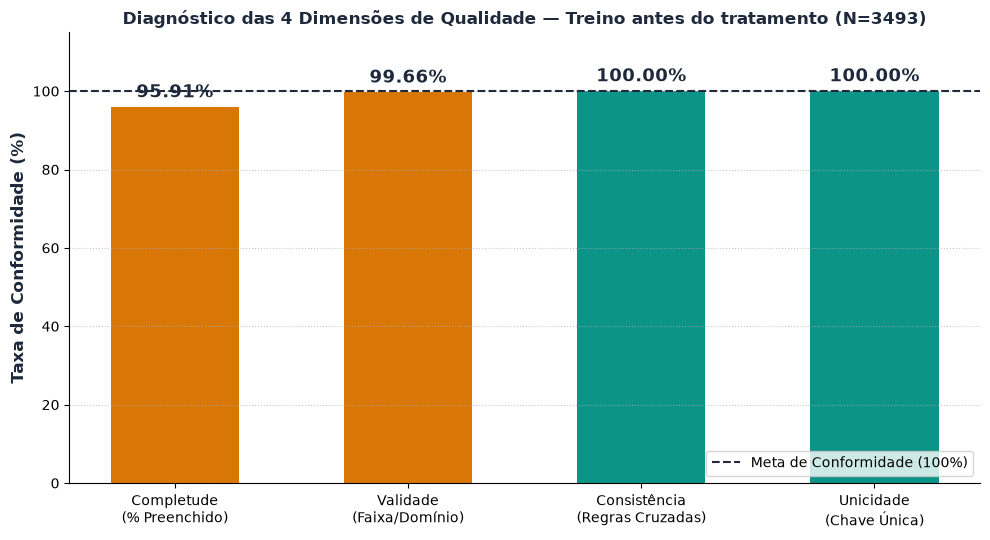

In [26]:
qualidade_antes = dimensoes_qualidade(treino)
grafico_qualidade(qualidade_antes, f'Diagnóstico das 4 Dimensões de Qualidade — Treino antes do tratamento (N={len(treino)})')

### Transformação da base de dados

#### Tratamento de dados discrepantes

Valores fora das faixas do inventário (mensalidade negativa ou muito alta, atrasos acima de 6) são considerados erro de registro e viram nulos (NaN), para serem preenchidos depois. É uma regra fixa, então é aplicada igual no treino e no teste.

In [27]:
# Guardando o treino antes do tratamento para comparar nos gráficos
treino_antes = treino.copy()

for base in [treino, teste]:
    # Substitui valores fora da faixa do inventário por nulos (NaN)
    for coluna, (minimo, maximo) in faixas.items():
        base[coluna] = base[coluna].where(base[coluna].between(minimo, maximo), np.nan)
    # Atrasos precisam ser números inteiros
    base['atrasos_6m'] = base['atrasos_6m'].where(base['atrasos_6m'] % 1 == 0, np.nan)

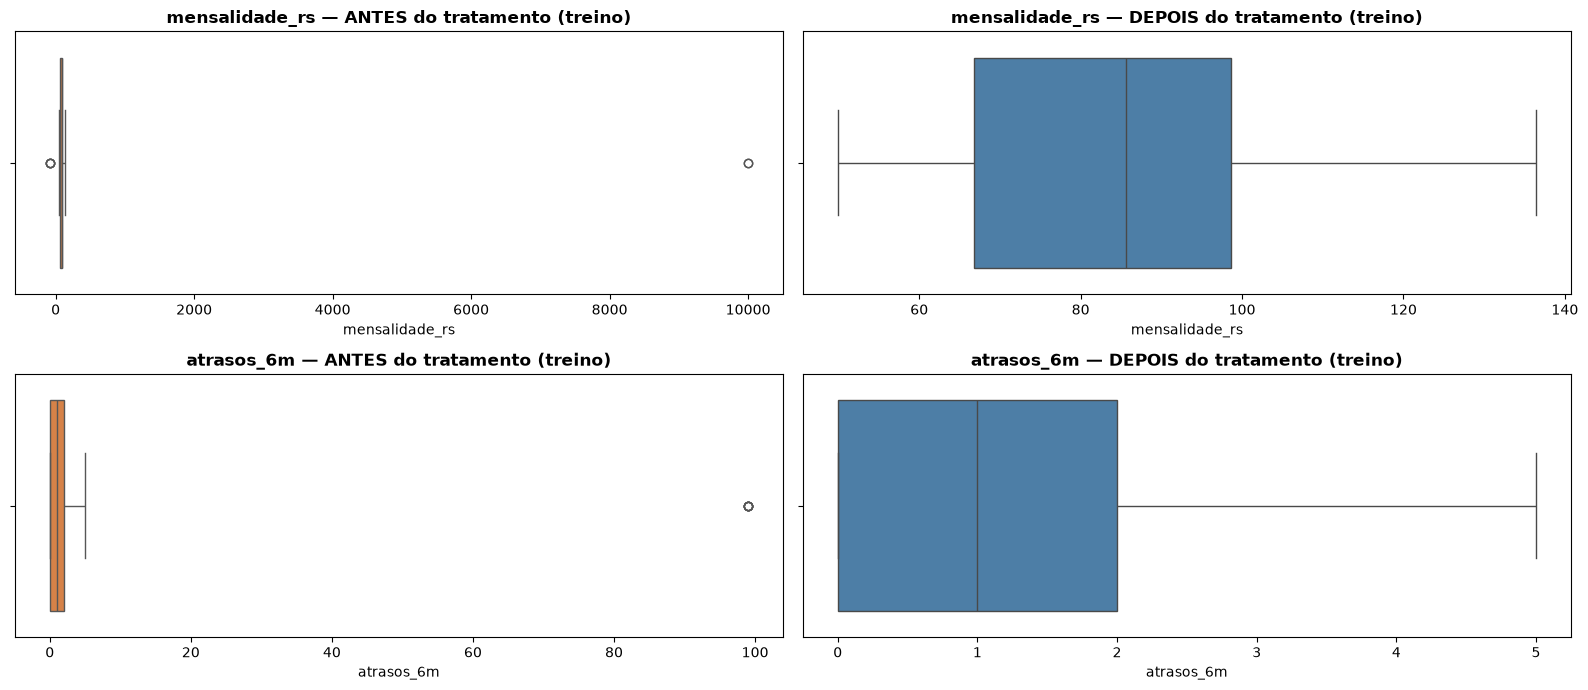

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(16, 7))
for linha, coluna in enumerate(['mensalidade_rs', 'atrasos_6m']):
    sns.boxplot(ax=axes[linha, 0], x=treino_antes[coluna], color='#ed7d31')
    axes[linha, 0].set_title(f'{coluna} — ANTES do tratamento (treino)', fontweight='bold')
    sns.boxplot(ax=axes[linha, 1], x=treino[coluna], color='#3e7fb5')
    axes[linha, 1].set_title(f'{coluna} — DEPOIS do tratamento (treino)', fontweight='bold')
plt.tight_layout()
plt.show()

#### Dimensões de qualidade depois do tratamento (antes do preenchimento)

,Dimensão,Regra,Conformidade
0,Completude,Registro sem valores faltantes,95.56%
1,Validade,Valores dentro da faixa/domínio do inventário,100.00%
2,Consistência,Data de aquisição não posterior à data de refe...,100.00%
3,Unicidade,Sem repetição de id_cliente + data_corte,100.00%


,Faltantes,Fora do inventário
mensalidade_rs,91,0
atrasos_6m,36,0
tipo_contrato,16,0
forma_pagamento,13,0


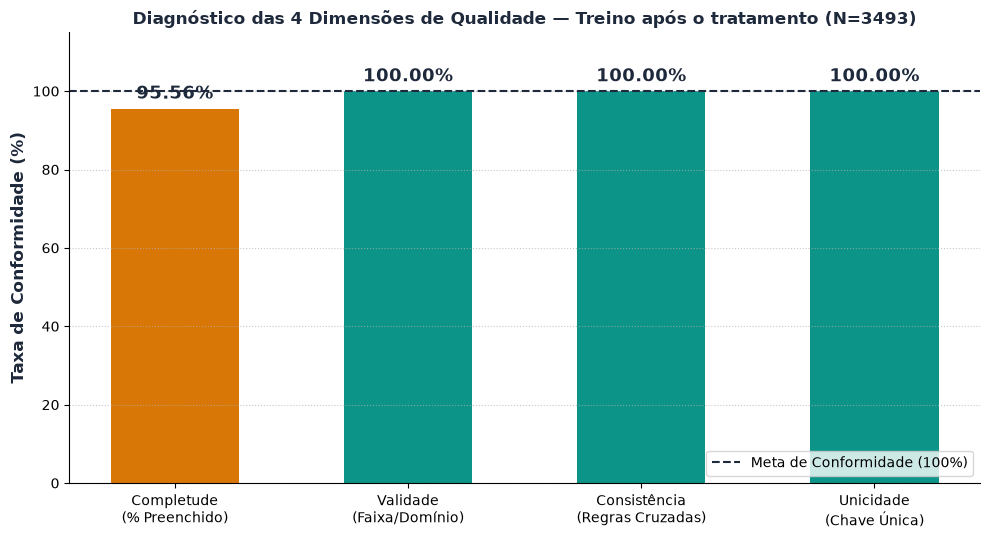

In [29]:
qualidade_depois = dimensoes_qualidade(treino)
grafico_qualidade(qualidade_depois, f'Diagnóstico das 4 Dimensões de Qualidade — Treino após o tratamento (N={len(treino)})')

Depois do de-para e da conversão dos valores discrepantes em nulos, a Validade chega a 100%. O que ainda falta para 100% é a Completude, que é resolvida no preenchimento com o KNNImputer.

#### Mecanismo dos dados faltantes

Comparando os clientes com e sem valor faltante no treino: se o perfil e a taxa de churn forem parecidos, há indício de MCAR; se a ausência tiver relação com outras colunas, MAR; se depender do próprio valor que falta, MNAR.

In [30]:
for coluna in ['mensalidade_rs', 'atrasos_6m', 'tempo_ativo_dias', 'tipo_contrato', 'forma_pagamento']:
    faltante = treino[coluna].isna()
    if faltante.sum() > 0:
        print(f"\n{coluna}: {faltante.sum()} faltantes ({faltante.mean():.2%})")
        display(treino.groupby(faltante.map({True: 'faltante', False: 'preenchido'}))
                [['churn', 'tempo_ativo_dias', 'qtd_chamados', 'fibra_optica', 'debito_automatico']].mean().round(3))


mensalidade_rs: 91 faltantes (2.61%)


,churn,tempo_ativo_dias,qtd_chamados,fibra_optica,debito_automatico
mensalidade_rs,,,,,
faltante,0.374,751.451,1.659,0.582,0.363
preenchido,0.354,750.195,1.707,0.564,0.396



atrasos_6m: 36 faltantes (1.03%)


,churn,tempo_ativo_dias,qtd_chamados,fibra_optica,debito_automatico
atrasos_6m,,,,,
faltante,0.250,768.917,1.722,0.500,0.583
preenchido,0.356,750.033,1.706,0.566,0.393



tipo_contrato: 16 faltantes (0.46%)


,churn,tempo_ativo_dias,qtd_chamados,fibra_optica,debito_automatico
tipo_contrato,,,,,
faltante,0.375,747.688,1.562,0.625,0.625
preenchido,0.355,750.240,1.706,0.565,0.394



forma_pagamento: 13 faltantes (0.37%)


,churn,tempo_ativo_dias,qtd_chamados,fibra_optica,debito_automatico
forma_pagamento,,,,,
faltante,0.615,744.308,1.846,0.615,0.462
preenchido,0.354,750.250,1.705,0.565,0.395


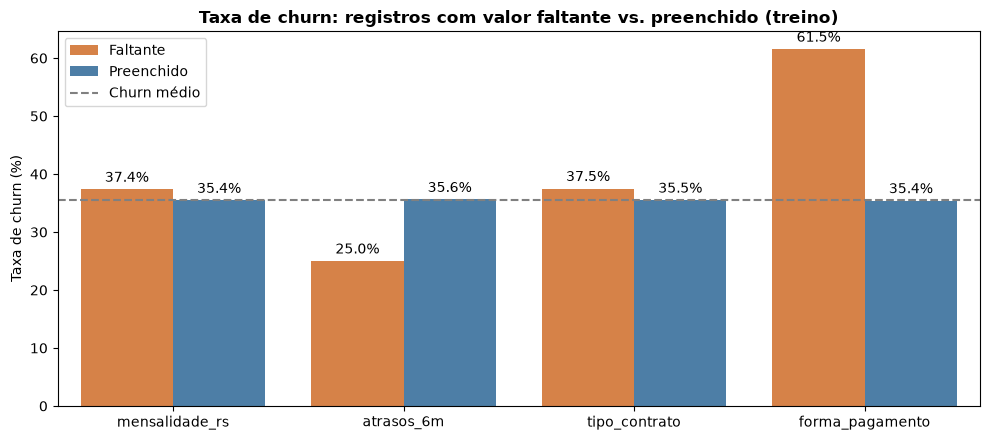

In [31]:
# Taxa de churn de quem tem o valor faltante vs. quem tem o valor preenchido
comparacao = []
for coluna in ['mensalidade_rs', 'atrasos_6m', 'tipo_contrato', 'forma_pagamento']:
    faltante = treino[coluna].isna()
    if faltante.sum() > 0:
        comparacao.append({'coluna': coluna, 'grupo': f'Faltante (n={faltante.sum()})', 'taxa': treino.loc[faltante, 'churn'].mean() * 100})
        comparacao.append({'coluna': coluna, 'grupo': 'Preenchido', 'taxa': treino.loc[~faltante, 'churn'].mean() * 100})
comparacao = pd.DataFrame(comparacao)
comparacao['tipo'] = comparacao['grupo'].str.split(' ').str[0]

plt.figure(figsize=(10, 4.5))
ax = sns.barplot(data=comparacao, x='coluna', y='taxa', hue='tipo', palette=['#ed7d31', '#3e7fb5'])
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.1f%%', padding=3)
ax.axhline(treino['churn'].mean() * 100, color='gray', linestyle='--', label='Churn médio')
ax.set_title('Taxa de churn: registros com valor faltante vs. preenchido (treino)', fontweight='bold')
ax.set_ylabel('Taxa de churn (%)')
ax.set_xlabel('')
ax.legend()
plt.tight_layout()
plt.show()

**Conclusão:**

- **Mensalidade (`mensalidade_rs`)** — 91 faltantes (2,61%), contando os valores discrepantes que viraram nulos. A ausência destes valores apresenta um padrão aleatório. O perfil dos clientes sem este dado é quase idêntico ao daqueles com o dado preenchido: taxa de churn de 37,4% contra 35,4%, tempo de cliente, chamados, fibra e débito automático muito parecidos. Tratamos como **MCAR**, e o preenchimento estatístico (via KNN) pode avançar sem risco de enviesamento.

- **Atrasos (`atrasos_6m`)** — 36 faltantes (1,03%). Os clientes sem o dado têm churn menor (25,0% contra 35,6%) e mais débito automático (58,3% contra 39,3%). Essa diferença pode indicar uma relação com o débito automático (**MAR**), mas o grupo é muito pequeno (36 clientes, só 9 com churn), então a diferença pode ser apenas acaso. Como o KNNImputer usa as outras colunas (incluindo o débito automático) para encontrar os vizinhos, ele já trata o caso MAR de forma adequada.

- **Tipo de contrato (`tipo_contrato`)** — 16 faltantes (0,46%). Taxa de churn de 37,5% contra 35,5% e perfil parecido com o dos preenchidos. Tratamos como **MCAR** e preenchemos com a moda do treino (Mensal).

- **Forma de pagamento (`forma_pagamento`)** — 13 faltantes (0,37%). A taxa de churn dos faltantes é bem maior (61,5% contra 35,4%), mas são apenas 13 clientes (8 com churn): uma diferença de poucas pessoas já muda muito a porcentagem, então não dá para afirmar que a ausência depende do churn. Pelo volume muito pequeno, o preenchimento com a moda do treino (Boleto) tem impacto mínimo na base. Fica o registro de que, se essa proporção se repetir em bases maiores, a ausência deve ser investigada na origem.

- **MNAR** (a ausência depender do próprio valor que falta, por exemplo clientes com mensalidade alta deixando de informar) não pode ser confirmado apenas com os dados disponíveis. Nada nas comparações acima indica esse comportamento.


#### Preenchimento de dados faltantes utilizando KNNImputer

Todas as etapas abaixo são ajustadas (`.fit`) somente no treino; o teste recebe apenas `.transform`.

In [32]:
numericas = ['tempo_ativo_dias', 'mensalidade_rs', 'qtd_chamados', 'atrasos_6m']
binarias_x = ['fibra_optica', 'debito_automatico']
categoricas = ['tipo_contrato', 'forma_pagamento']

# 1. Preenche os nulos das colunas de texto com a moda do treino
moda_treino = treino[categoricas].mode().iloc[0]
print("Moda do treino:", moda_treino.to_dict())
for base in [treino, teste]:
    base[categoricas] = base[categoricas].fillna(moda_treino)

# 2. One-Hot Encoding aprendido no treino (categorias novas no teste são ignoradas)
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(treino[categoricas])
colunas_dummies = encoder.get_feature_names_out(categoricas)

def montar_features(base):
    dummies = pd.DataFrame(encoder.transform(base[categoricas]), columns=colunas_dummies, index=base.index)
    return pd.concat([base[numericas + binarias_x], dummies], axis=1)

X_treino = montar_features(treino)
X_teste = montar_features(teste)

Moda do treino: {'tipo_contrato': 'Mensal', 'forma_pagamento': 'Boleto'}


In [33]:
# 3. Inicializar o modelo KNN (utilizando 5 vizinhos como padrão), ajustar no treino e aplicar no teste
imputer = KNNImputer(n_neighbors=5)
imputer.fit(X_treino)

# O índice é mantido para cada valor voltar para a linha certa
X_treino = pd.DataFrame(imputer.transform(X_treino), columns=X_treino.columns, index=X_treino.index)
X_teste = pd.DataFrame(imputer.transform(X_teste), columns=X_teste.columns, index=X_teste.index)

# Atrasos voltam a ser número inteiro
X_treino['atrasos_6m'] = X_treino['atrasos_6m'].round()
X_teste['atrasos_6m'] = X_teste['atrasos_6m'].round()

print("Faltantes restantes no treino:", X_treino.isna().sum().sum())
print("Faltantes restantes no teste:", X_teste.isna().sum().sum())

Faltantes restantes no treino: 0
Faltantes restantes no teste: 0


### Exploração dos dados (dados tratados)

A exploração é feita só com o treino, para que o teste não influencie nenhuma decisão.

In [34]:
# Base de treino tratada (ainda sem padronização) para a exploração
treino_tratado = pd.concat([X_treino, treino['churn']], axis=1)

print("Informações gerais da base de dados:")
treino_tratado.info()

Informações gerais da base de dados:
<class 'pandas.DataFrame'>
RangeIndex: 3493 entries, 0 to 3492
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   tempo_ativo_dias        3493 non-null   float64
 1   mensalidade_rs          3493 non-null   float64
 2   qtd_chamados            3493 non-null   float64
 3   atrasos_6m              3493 non-null   float64
 4   fibra_optica            3493 non-null   float64
 5   debito_automatico       3493 non-null   float64
 6   tipo_contrato_Anual     3493 non-null   float64
 7   tipo_contrato_Bienal    3493 non-null   float64
 8   tipo_contrato_Mensal    3493 non-null   float64
 9   forma_pagamento_Boleto  3493 non-null   float64
 10  forma_pagamento_Cartão  3493 non-null   float64
 11  forma_pagamento_Pix     3493 non-null   float64
 12  churn                   3493 non-null   int64  
dtypes: float64(12), int64(1)
memory usage: 354.9 KB


In [35]:
print("Estatísticas descritivas das colunas numéricas:")
treino_tratado.describe()

Estatísticas descritivas das colunas numéricas:


,tempo_ativo_dias,mensalidade_rs,qtd_chamados,atrasos_6m,fibra_optica,debito_automatico,tipo_contrato_Anual,tipo_contrato_Bienal,tipo_contrato_Mensal,forma_pagamento_Boleto,forma_pagamento_Cartão,forma_pagamento_Pix,churn
count,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000,3493.000000
mean,750.227884,83.336424,1.705697,1.052390,0.564844,0.394790,0.237904,0.200973,0.561122,0.391640,0.347839,0.260521,0.354996
std,468.162555,18.270763,1.426257,0.949078,0.495848,0.488875,0.425861,0.400786,0.496321,0.488187,0.476353,0.438982,0.478581
min,31.000000,49.900000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,396.000000,67.040000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,639.000000,85.600000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
75%,1005.000000,98.400000,2.000000,2.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,2191.000000,136.420000,10.000000,5.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [36]:
print(f"Prevalência de churn no treino: {treino_tratado['churn'].mean():.2%}")

Prevalência de churn no treino: 35.50%


#### Distribuição das variáveis numéricas por churn

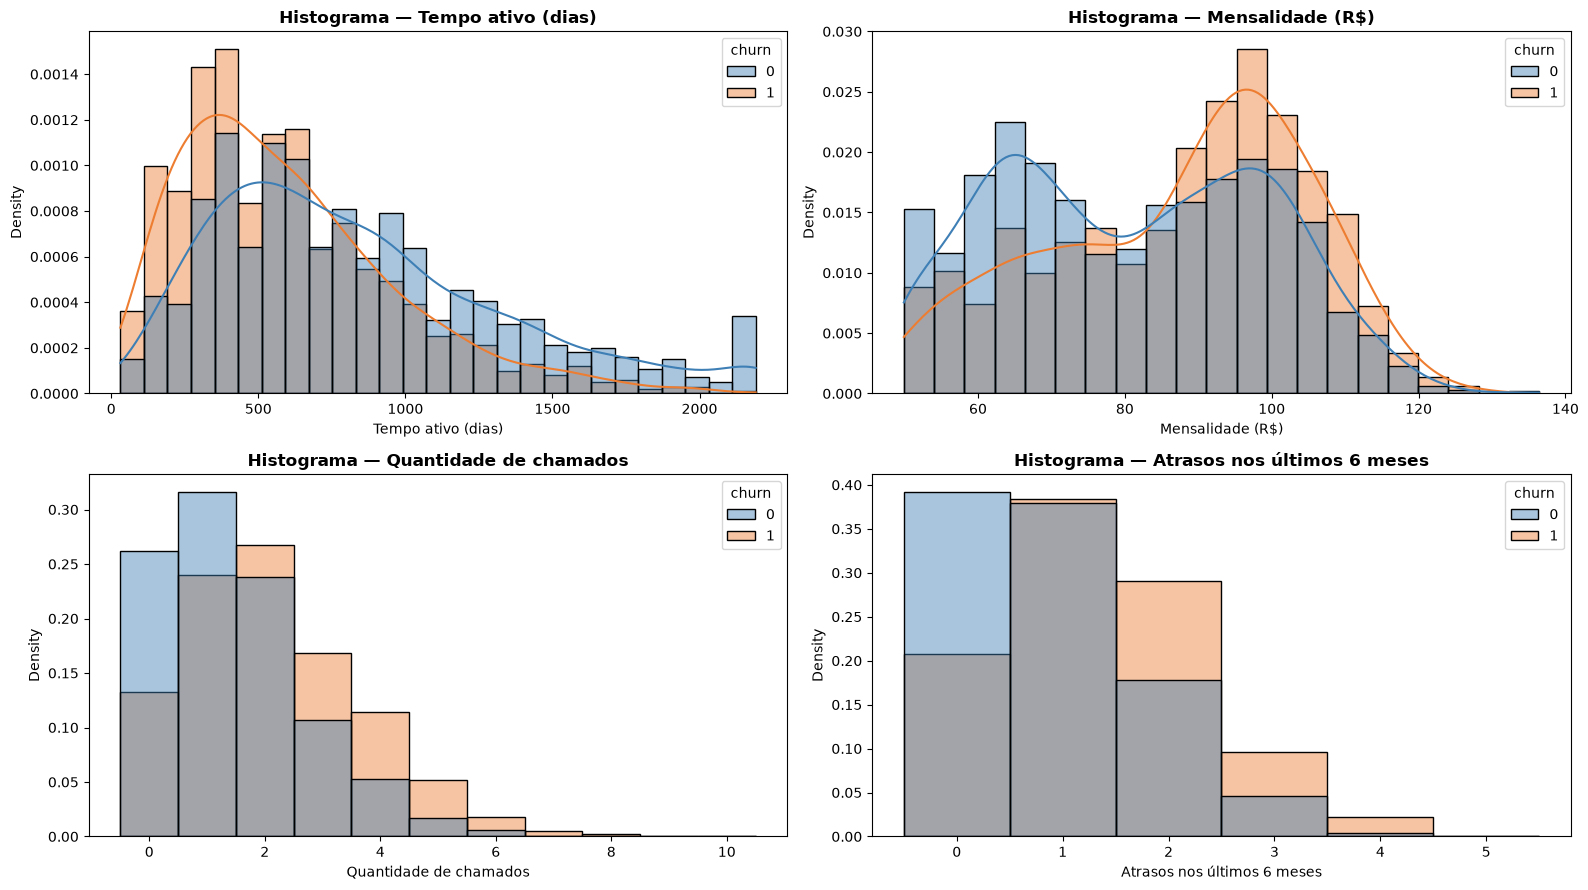

In [37]:
titulos = {'tempo_ativo_dias': 'Tempo ativo (dias)', 'mensalidade_rs': 'Mensalidade (R$)',
           'qtd_chamados': 'Quantidade de chamados', 'atrasos_6m': 'Atrasos nos últimos 6 meses'}

# Histograma com curva de densidade (KDE), normalizado dentro de cada classe
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, coluna in zip(axes.flatten(), numericas):
    discreta = coluna in ['qtd_chamados', 'atrasos_6m']
    sns.histplot(ax=ax, data=treino_tratado, x=coluna, hue='churn', stat='density', common_norm=False,
                 discrete=discreta, kde=not discreta, palette=CORES, alpha=0.45)
    ax.set_title(f'Histograma — {titulos[coluna]}', fontweight='bold')
    ax.set_xlabel(titulos[coluna])
plt.tight_layout()
plt.show()

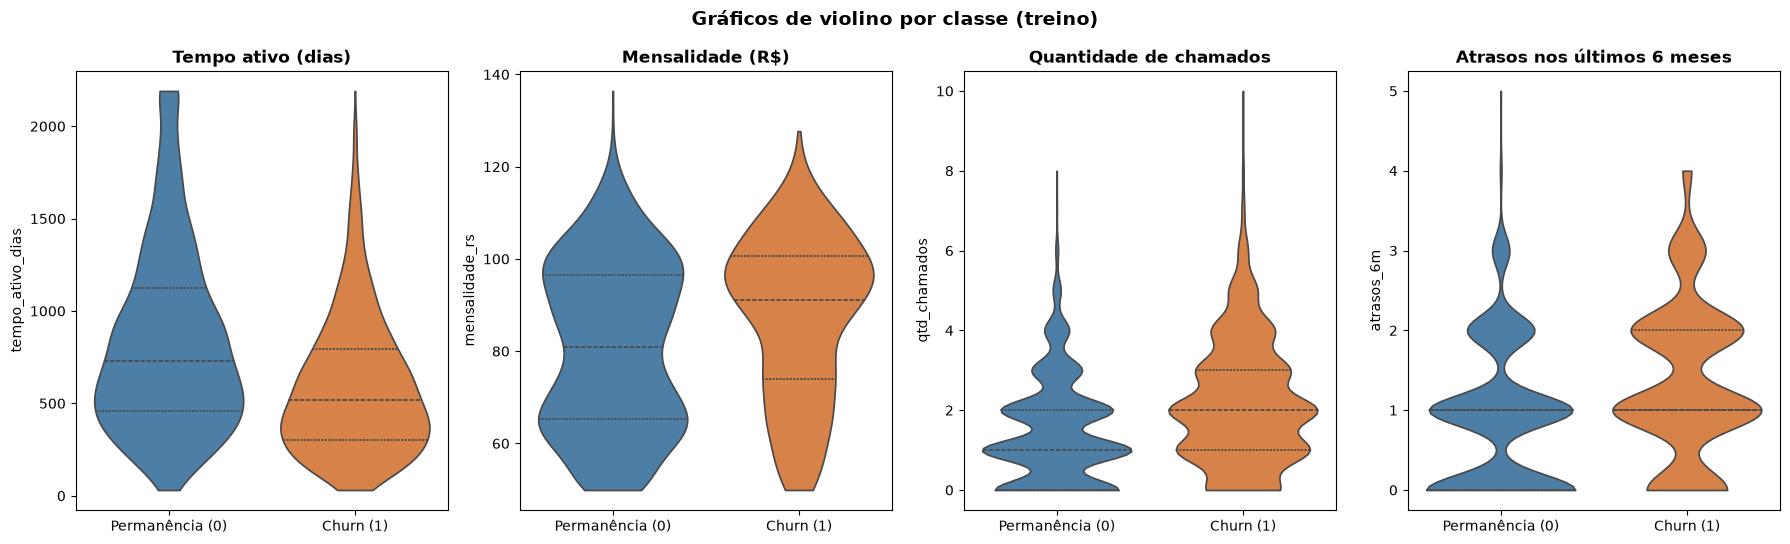

In [38]:
# Gráfico de violino: formato da distribuição + quartis de cada classe
fig, axes = plt.subplots(1, 4, figsize=(18, 5.5))
for ax, coluna in zip(axes, numericas):
    sns.violinplot(ax=ax, data=treino_tratado, x='churn', y=coluna, hue='churn', palette=CORES,
                   inner='quartile', cut=0, legend=False)
    ax.set_title(titulos[coluna], fontweight='bold')
    ax.set_xticks([0, 1], ['Permanência (0)', 'Churn (1)'])
    ax.set_xlabel('')
plt.suptitle('Gráficos de violino por classe (treino)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

No violino, a largura mostra onde os clientes se concentram e as linhas internas são os quartis. Quem cancela se concentra em tempos de cliente menores e em mais chamados e atrasos.

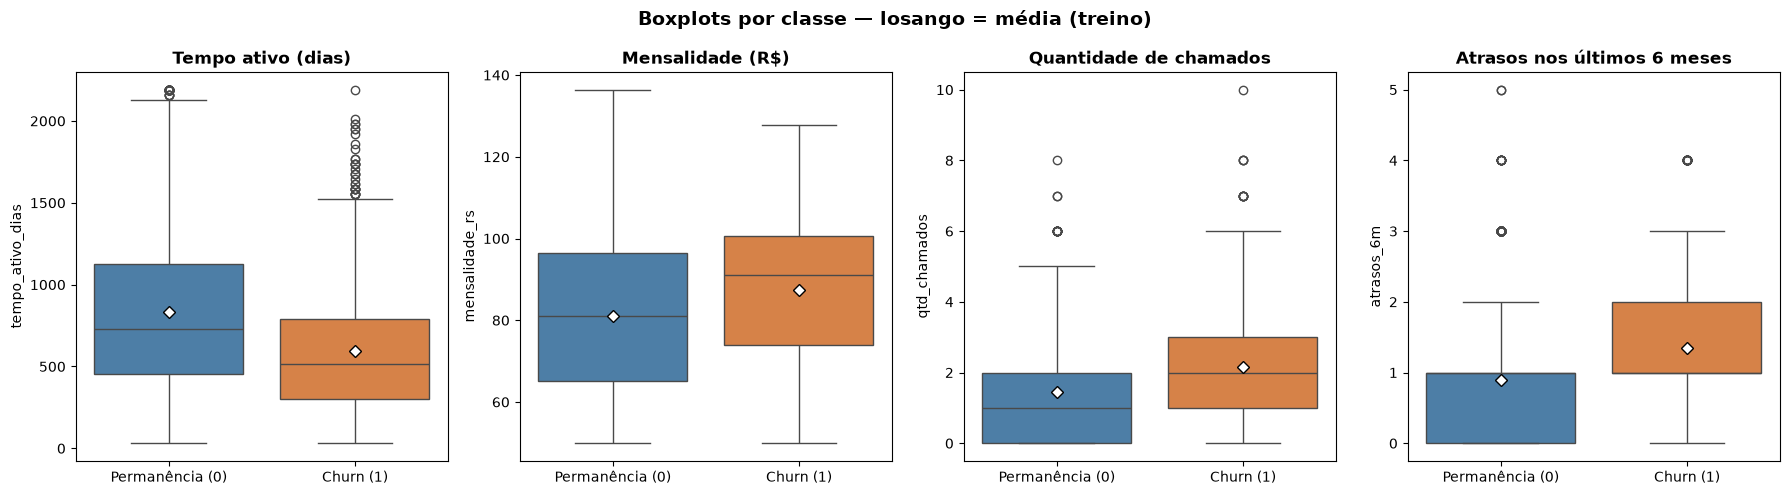

In [39]:
# Boxplot por classe com a média marcada
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, coluna in zip(axes, numericas):
    sns.boxplot(ax=ax, data=treino_tratado, x='churn', y=coluna, hue='churn', palette=CORES, legend=False,
                showmeans=True, meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black'})
    ax.set_title(titulos[coluna], fontweight='bold')
    ax.set_xticks([0, 1], ['Permanência (0)', 'Churn (1)'])
    ax.set_xlabel('')
plt.suptitle('Boxplots por classe — losango = média (treino)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### Distribuições acumuladas (CDF) e estatística KS por variável

Mesmo tipo de gráfico do teste Kolmogorov-Smirnov da Aula 3: a linha vermelha mostra a maior distância vertical entre as curvas acumuladas de churn e permanência. Quanto maior o KS, mais a variável separa as duas classes.

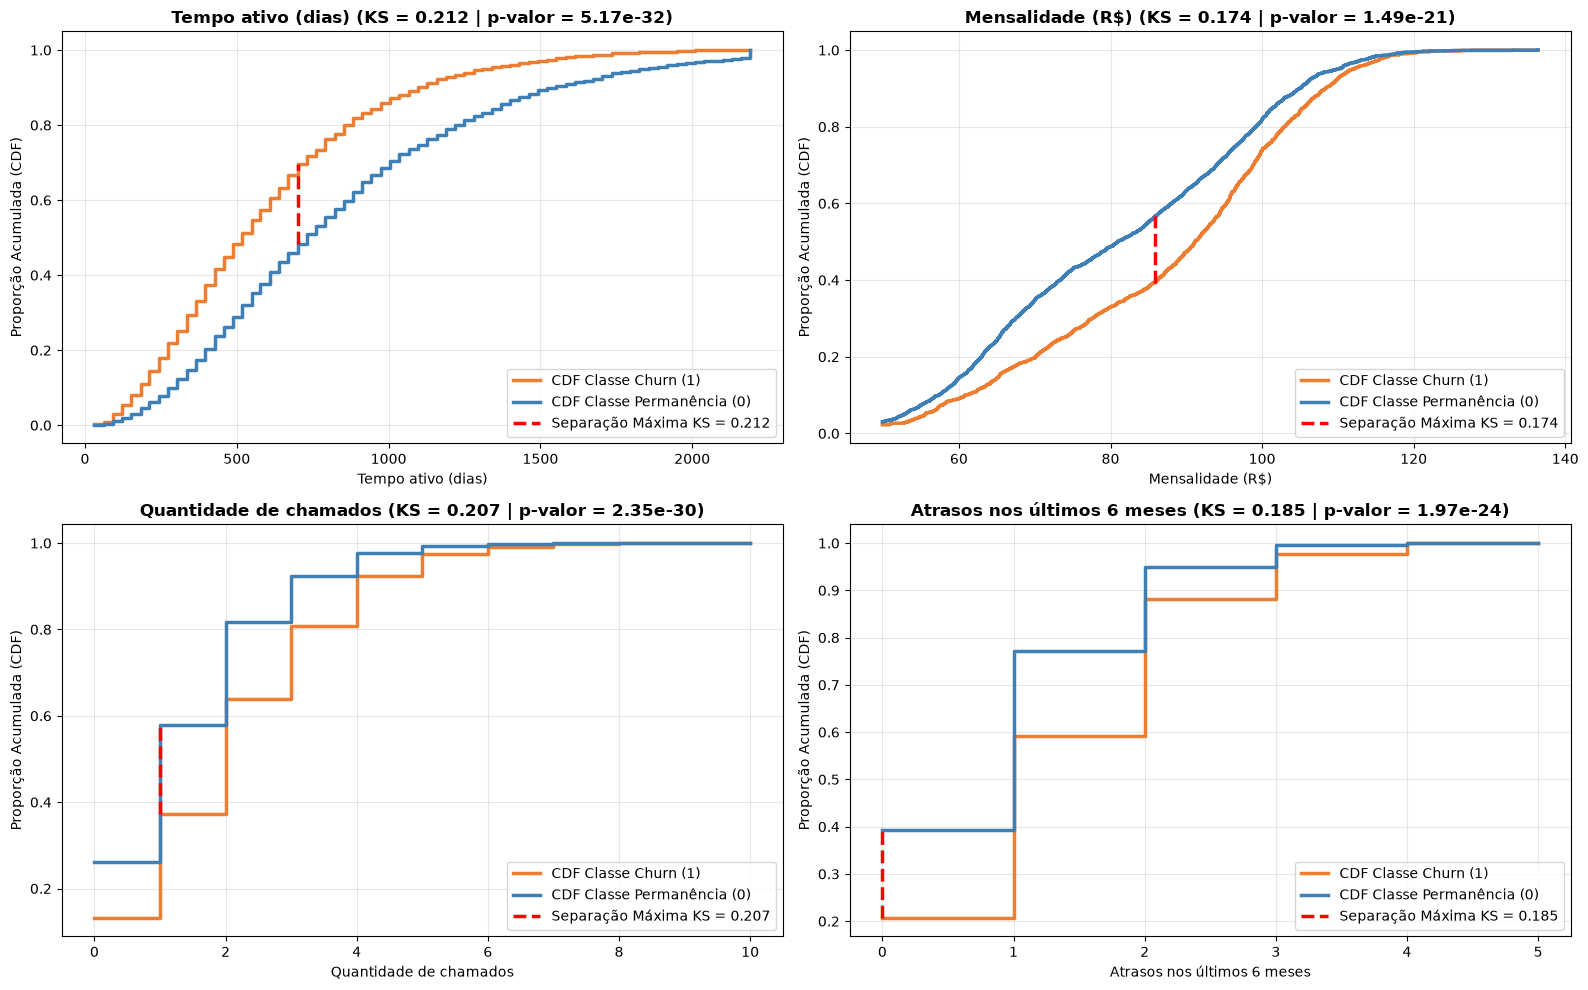

,variável,KS,p-valor
0,tempo_ativo_dias,0.2122,0.0
2,qtd_chamados,0.2066,0.0
3,atrasos_6m,0.1851,0.0
1,mensalidade_rs,0.1737,0.0


In [40]:
from scipy.stats import ks_2samp

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
resultado_ks = []
for ax, coluna in zip(axes.flatten(), numericas):
    churn1 = treino_tratado.loc[treino_tratado['churn'] == 1, coluna]
    churn0 = treino_tratado.loc[treino_tratado['churn'] == 0, coluna]
    ks, p_valor = ks_2samp(churn1, churn0)
    resultado_ks.append({'variável': coluna, 'KS': ks, 'p-valor': p_valor})

    grade = np.sort(treino_tratado[coluna].unique())
    cdf1 = np.searchsorted(np.sort(churn1), grade, side='right') / len(churn1)
    cdf0 = np.searchsorted(np.sort(churn0), grade, side='right') / len(churn0)
    k = np.argmax(np.abs(cdf1 - cdf0))

    ax.step(grade, cdf1, where='post', color=CORES[1], linewidth=2.5, label='CDF Classe Churn (1)')
    ax.step(grade, cdf0, where='post', color=CORES[0], linewidth=2.5, label='CDF Classe Permanência (0)')
    ax.vlines(grade[k], min(cdf1[k], cdf0[k]), max(cdf1[k], cdf0[k]), colors='red', linestyles='--', linewidth=2.5,
              label=f'Separação Máxima KS = {ks:.3f}')
    ax.set_title(f'{titulos[coluna]} (KS = {ks:.3f} | p-valor = {p_valor:.2e})', fontweight='bold')
    ax.set_xlabel(titulos[coluna])
    ax.set_ylabel('Proporção Acumulada (CDF)')
    ax.grid(alpha=0.3)
    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

display(pd.DataFrame(resultado_ks).sort_values('KS', ascending=False).round(4))

#### Variáveis categóricas e binárias vs. churn

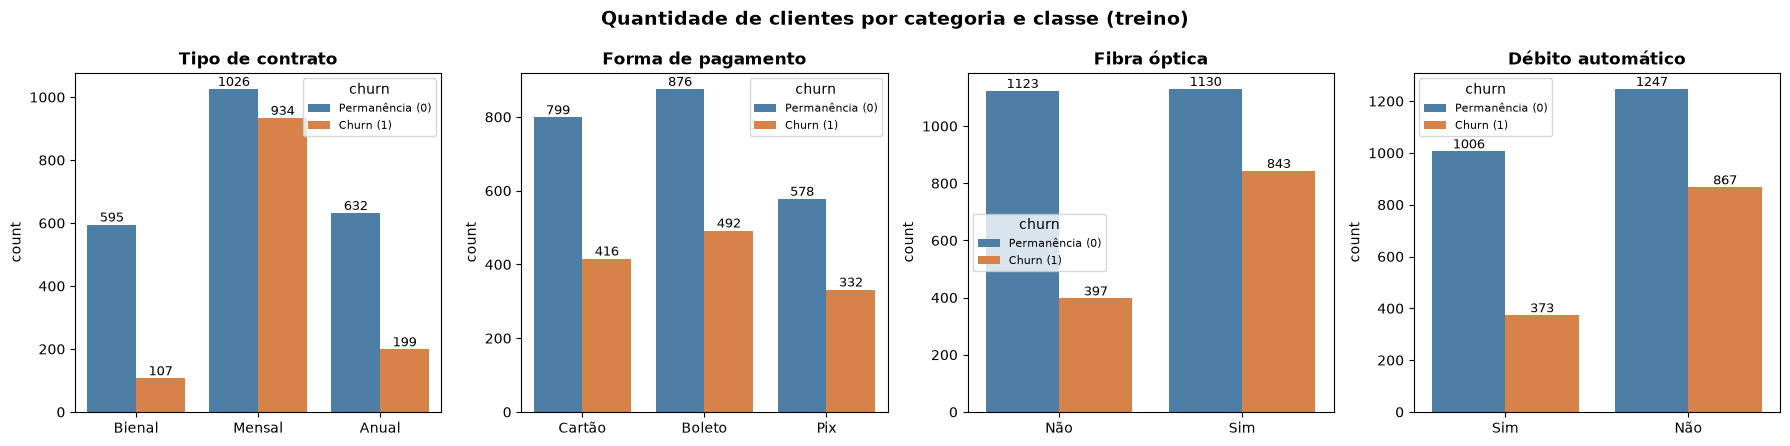

In [41]:
# Junta as categorias (já sem faltantes) com o churn do treino
treino_categorias = treino[categoricas + binarias_x + ['churn']].copy()
treino_categorias[binarias_x] = treino_categorias[binarias_x].replace({0: 'Não', 1: 'Sim'})
nomes = {'tipo_contrato': 'Tipo de contrato', 'forma_pagamento': 'Forma de pagamento',
         'fibra_optica': 'Fibra óptica', 'debito_automatico': 'Débito automático'}

# Gráfico de contagem (countplot): quantidade de clientes por categoria e classe
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, coluna in zip(axes, categoricas + binarias_x):
    sns.countplot(ax=ax, data=treino_categorias, x=coluna, hue='churn', palette=CORES)
    for barras in ax.containers:
        ax.bar_label(barras, fontsize=9)
    ax.set_title(nomes[coluna], fontweight='bold')
    ax.set_xlabel('')
    ax.legend(title='churn', labels=['Permanência (0)', 'Churn (1)'], fontsize=8)
plt.suptitle('Quantidade de clientes por categoria e classe (treino)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

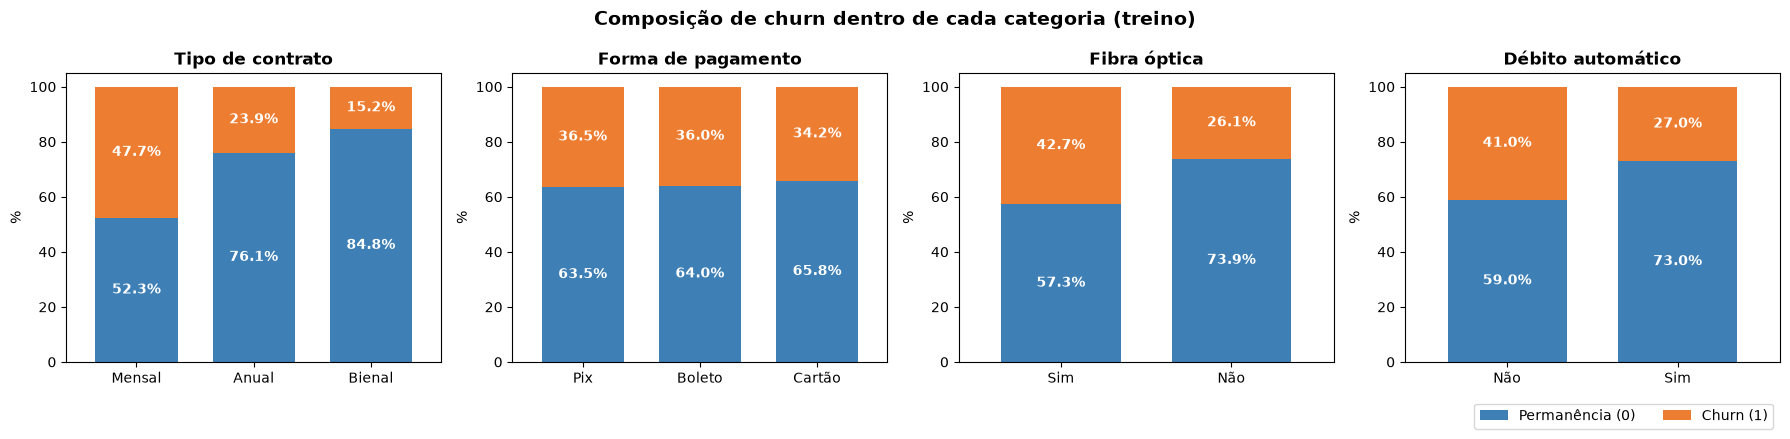

In [42]:
# Barras empilhadas 100%: composição de churn dentro de cada categoria
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, coluna in zip(axes, categoricas + binarias_x):
    composicao = pd.crosstab(treino_categorias[coluna], treino_categorias['churn'], normalize='index') * 100
    composicao = composicao.sort_values(1, ascending=False)
    composicao.plot(kind='bar', stacked=True, ax=ax, color=CORES, rot=0, legend=False, width=0.7)
    for barras in ax.containers:
        ax.bar_label(barras, fmt='%.1f%%', label_type='center', color='white', fontweight='bold')
    ax.set_title(nomes[coluna], fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('%')
axes[-1].legend(['Permanência (0)', 'Churn (1)'], loc='upper right', bbox_to_anchor=(1.0, -0.12), ncol=2)
plt.suptitle('Composição de churn dentro de cada categoria (treino)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

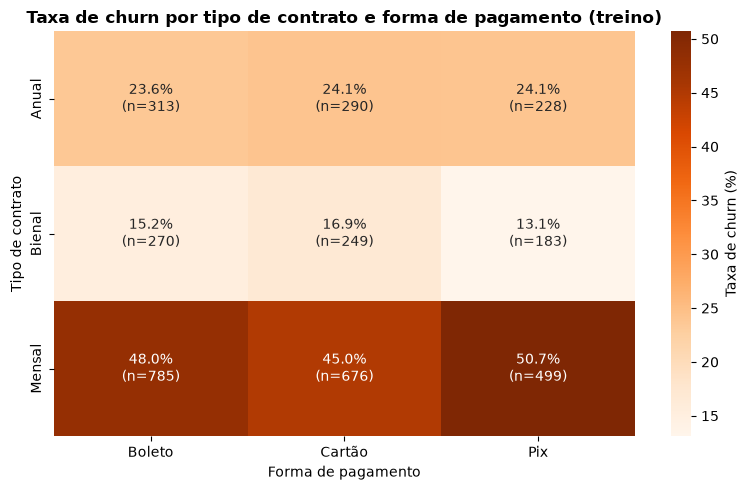

In [43]:
# Mapa de calor: taxa de churn combinando tipo de contrato e forma de pagamento
taxa_cruzada = treino_categorias.pivot_table(index='tipo_contrato', columns='forma_pagamento', values='churn', aggfunc='mean') * 100
quantidade = treino_categorias.pivot_table(index='tipo_contrato', columns='forma_pagamento', values='churn', aggfunc='size')
rotulos = taxa_cruzada.round(1).astype(str) + '%\n(n=' + quantidade.astype(str) + ')'

plt.figure(figsize=(8, 5))
sns.heatmap(taxa_cruzada, annot=rotulos, fmt='', cmap='Oranges', cbar_kws={'label': 'Taxa de churn (%)'})
plt.title('Taxa de churn por tipo de contrato e forma de pagamento (treino)', fontweight='bold')
plt.ylabel('Tipo de contrato')
plt.xlabel('Forma de pagamento')
plt.tight_layout()
plt.show()

#### Taxa de churn por tempo de cliente e por quantidade de chamados

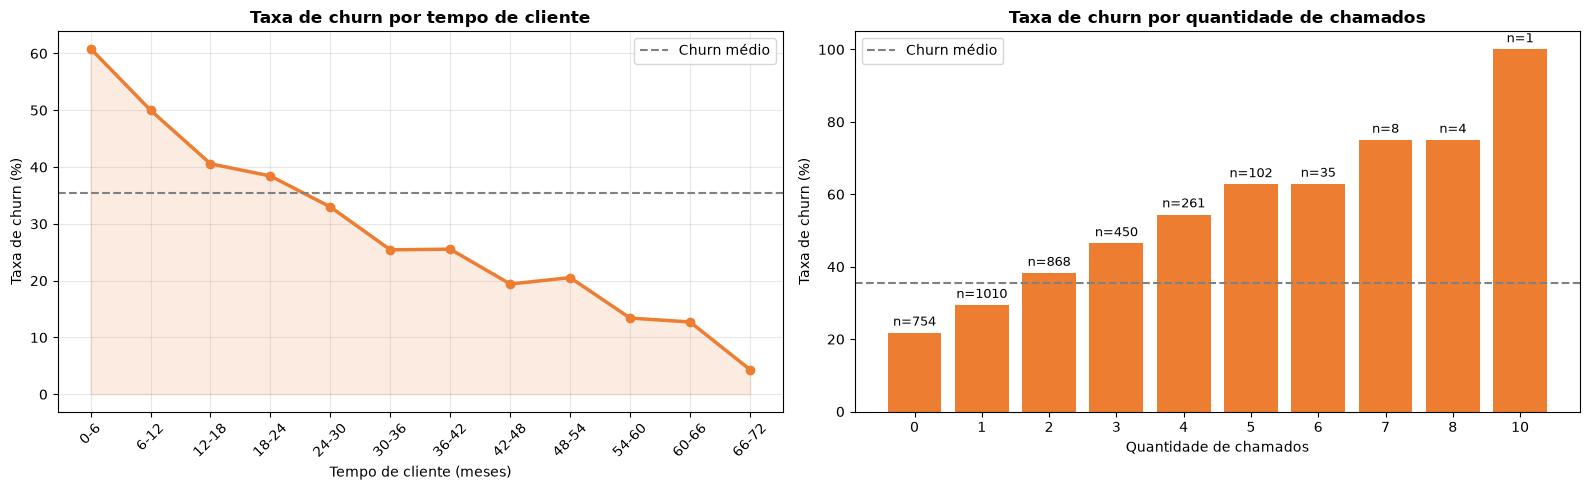

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico de linha: tempo em faixas de 6 meses
faixa_tempo = pd.cut(treino_tratado['tempo_ativo_dias'] / 30, bins=range(0, 78, 6), right=False)
taxa_tempo = treino_tratado.groupby(faixa_tempo, observed=True)['churn'].mean() * 100
rotulos_tempo = [f'{int(f.left)}-{int(f.right)}' for f in taxa_tempo.index]
axes[0].plot(rotulos_tempo, taxa_tempo.values, marker='o', color=CORES[1], linewidth=2.5)
axes[0].fill_between(rotulos_tempo, taxa_tempo.values, alpha=0.15, color=CORES[1])
axes[0].axhline(treino['churn'].mean() * 100, color='gray', linestyle='--', label='Churn médio')
axes[0].set_title('Taxa de churn por tempo de cliente', fontweight='bold')
axes[0].set_xlabel('Tempo de cliente (meses)')
axes[0].set_ylabel('Taxa de churn (%)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(alpha=0.3)
axes[0].legend()

# Gráfico de barras: quantidade de chamados (n = clientes no grupo)
taxa_chamados = treino_tratado.groupby('qtd_chamados')['churn'].agg(['mean', 'size'])
barras = axes[1].bar(taxa_chamados.index.astype(int).astype(str), taxa_chamados['mean'] * 100, color=CORES[1])
axes[1].bar_label(barras, labels=[f'n={n}' for n in taxa_chamados['size']], padding=3, fontsize=9)
axes[1].axhline(treino['churn'].mean() * 100, color='gray', linestyle='--', label='Churn médio')
axes[1].set_title('Taxa de churn por quantidade de chamados', fontweight='bold')
axes[1].set_xlabel('Quantidade de chamados')
axes[1].set_ylabel('Taxa de churn (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

#### Relação entre pares de variáveis

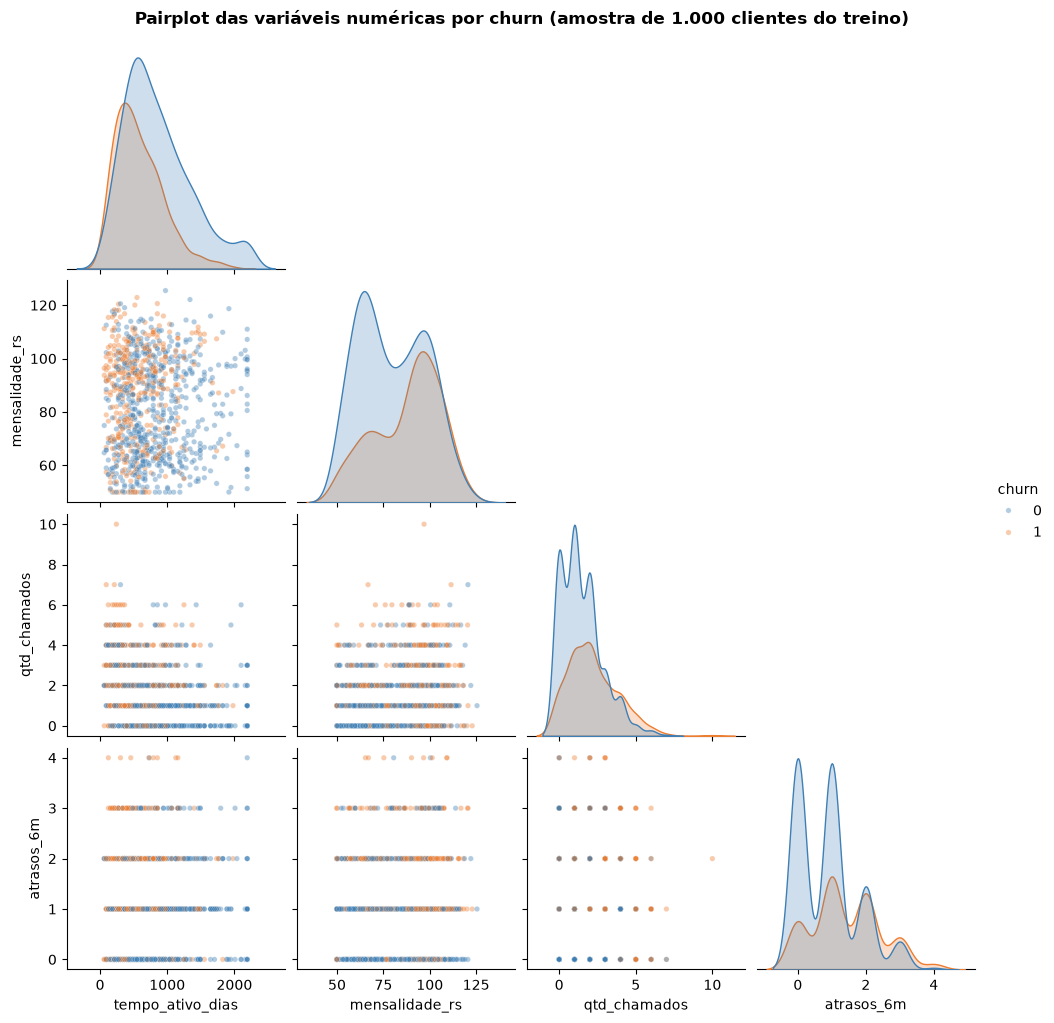

In [45]:
# Gráfico de pares (pairplot): dispersão entre cada par de variáveis e distribuição de cada uma
amostra = treino_tratado[numericas + ['churn']].sample(1000, random_state=42)
grafico = sns.pairplot(amostra, hue='churn', palette=CORES, corner=True, diag_kind='kde',
                       plot_kws={'alpha': 0.4, 's': 15})
grafico.figure.suptitle('Pairplot das variáveis numéricas por churn (amostra de 1.000 clientes do treino)', fontweight='bold', y=1.02)
plt.show()

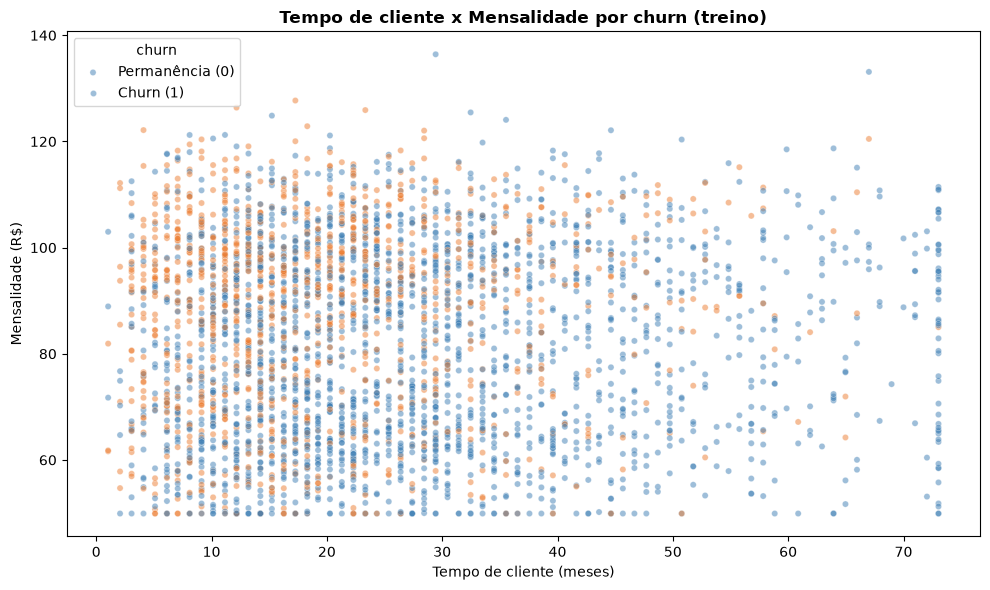

In [46]:
# Dispersão: tempo de cliente x mensalidade, colorido por churn
plt.figure(figsize=(10, 6))
sns.scatterplot(data=treino_tratado, x=treino_tratado['tempo_ativo_dias'] / 30, y='mensalidade_rs', hue='churn',
                palette=CORES, alpha=0.5, s=20)
plt.title('Tempo de cliente x Mensalidade por churn (treino)', fontweight='bold')
plt.xlabel('Tempo de cliente (meses)')
plt.ylabel('Mensalidade (R$)')
plt.legend(title='churn', labels=['Permanência (0)', 'Churn (1)'])
plt.tight_layout()
plt.show()

#### Matriz de correlação de Pearson

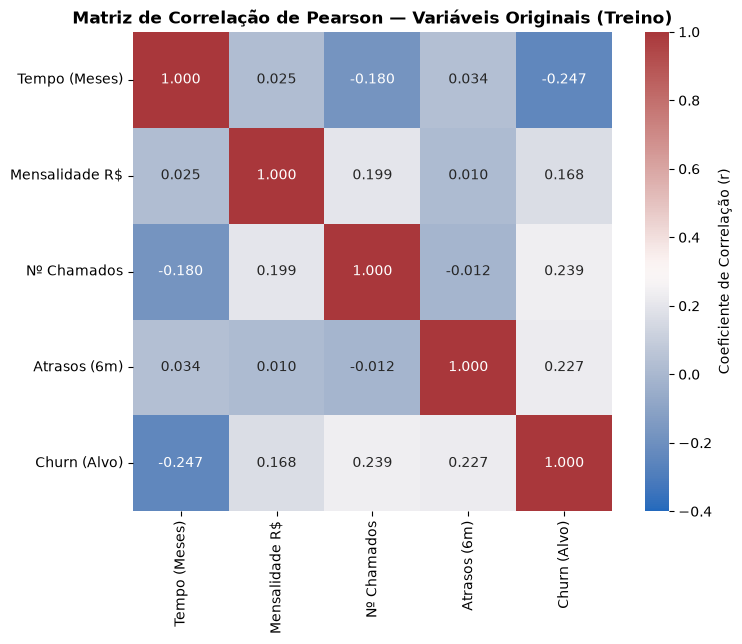

Tempo (Meses)    -0.247
Nº Chamados       0.239
Atrasos (6m)      0.227
Mensalidade R$    0.168
Name: Churn (Alvo), dtype: float64


In [47]:
# Mesmo formato do slide "Matriz de Correlação de Pearson — Variáveis Numéricas Originais" (Aula 3)
originais = pd.DataFrame({
    'Tempo (Meses)': treino_tratado['tempo_ativo_dias'] / 30,
    'Mensalidade R$': treino_tratado['mensalidade_rs'],
    'Nº Chamados': treino_tratado['qtd_chamados'],
    'Atrasos (6m)': treino_tratado['atrasos_6m'],
    'Churn (Alvo)': treino_tratado['churn'],
})
correlacao = originais.corr(method='pearson')

plt.figure(figsize=(8, 6.5))
sns.heatmap(correlacao, annot=True, fmt='.3f', cmap='vlag', vmin=-0.4, vmax=1.0, square=True,
            cbar_kws={'label': 'Coeficiente de Correlação (r)'})
plt.title('Matriz de Correlação de Pearson — Variáveis Originais (Treino)', fontweight='bold')
plt.tight_layout()
plt.show()

print(correlacao['Churn (Alvo)'].drop('Churn (Alvo)').sort_values(key=abs, ascending=False).round(3))

**Diagnóstico das variáveis originais:**
- `qtd_chamados` e `atrasos_6m` têm associação linear positiva com o churn (mais chamados e mais atrasos, maior o risco).
- `tempo_ativo_dias` tem correlação negativa: é o principal fator de proteção (quanto mais antigo o cliente, menor a chance de cancelar).
- `mensalidade_rs` tem correlação positiva mais baixa na escala contínua.

#### Análises Adicionais: Chamados e Atrasos vs Churn

Vamos analisar visualmente como a quantidade de chamados (`qtd_chamados`) e a quantidade de faturas atrasadas nos últimos 6 meses (`atrasos_6m`) se relacionam com o Churn dos clientes.

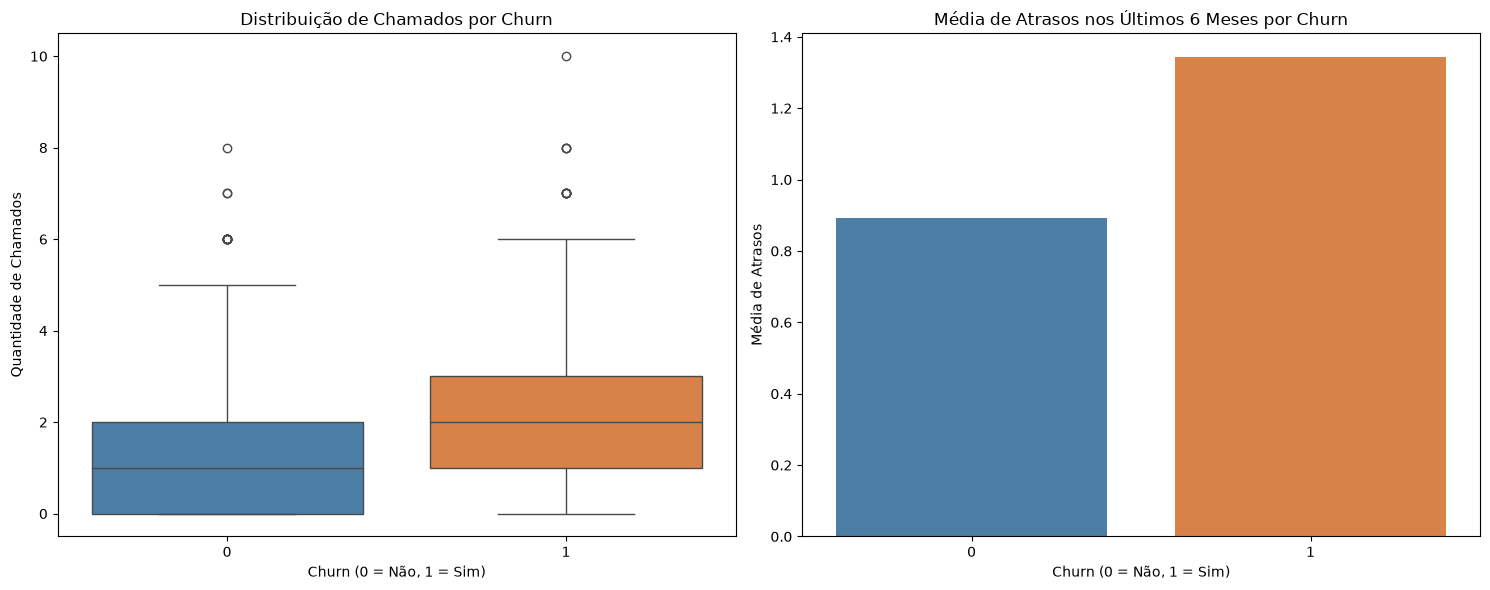

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Quantidade de chamados por Churn
sns.boxplot(ax=axes[0], data=treino_tratado, x='churn', y='qtd_chamados', hue='churn', palette=CORES, legend=False)
axes[0].set_title('Distribuição de Chamados por Churn')
axes[0].set_xlabel('Churn (0 = Não, 1 = Sim)')
axes[0].set_ylabel('Quantidade de Chamados')

# Gráfico 2: Média de Atrasos por Churn
sns.barplot(ax=axes[1], data=treino_tratado, x='churn', y='atrasos_6m', hue='churn', palette=CORES, errorbar=None, legend=False)
axes[1].set_title('Média de Atrasos nos Últimos 6 Meses por Churn')
axes[1].set_xlabel('Churn (0 = Não, 1 = Sim)')
axes[1].set_ylabel('Média de Atrasos')

plt.tight_layout()
plt.show()

#### Combo Risco Triplo (tempo <= 18 meses, chamados >= 2 e atrasos >= 1)

In [49]:
combo = ((treino_tratado['tempo_ativo_dias'] <= 18 * 30) &
         (treino_tratado['qtd_chamados'] >= 2) &
         (treino_tratado['atrasos_6m'] >= 1)).astype(int)

print(f"Clientes no combo: {combo.sum()} ({combo.mean():.2%})")
print(f"Churn dentro do combo: {treino_tratado.loc[combo == 1, 'churn'].mean():.2%}")
print(f"Churn fora do combo: {treino_tratado.loc[combo == 0, 'churn'].mean():.2%}")
print(f"Correlação com churn: {combo.corr(treino_tratado['churn']):.3f}")

Clientes no combo: 534 (15.29%)
Churn dentro do combo: 63.11%
Churn fora do combo: 30.52%
Correlação com churn: 0.245


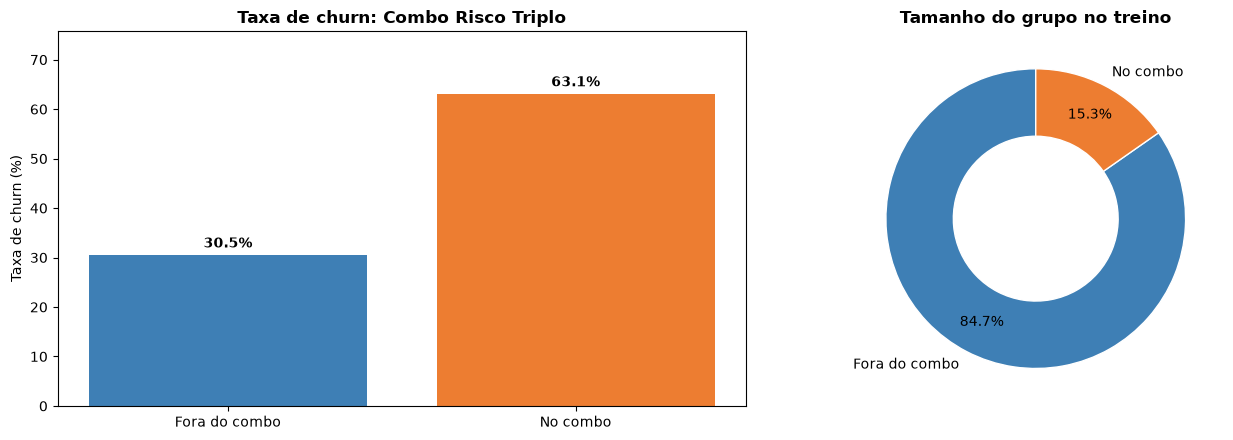

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

taxa_combo = treino_tratado.groupby(combo.map({1: 'No combo', 0: 'Fora do combo'}))['churn'].mean() * 100
axes[0].bar(taxa_combo.index, taxa_combo.values, color=[CORES[0], CORES[1]])
axes[0].bar_label(axes[0].containers[0], fmt='%.1f%%', padding=3, fontweight='bold')
axes[0].set_ylim(0, taxa_combo.max() * 1.2)
axes[0].set_title('Taxa de churn: Combo Risco Triplo', fontweight='bold')
axes[0].set_ylabel('Taxa de churn (%)')

tamanho = combo.map({1: 'No combo', 0: 'Fora do combo'}).value_counts()
axes[1].pie(tamanho, labels=tamanho.index, colors=[CORES[0], CORES[1]], autopct='%1.1f%%', startangle=90,
            wedgeprops={'width': 0.45, 'edgecolor': 'white'}, pctdistance=0.78)
axes[1].set_title('Tamanho do grupo no treino', fontweight='bold')

plt.tight_layout()
plt.show()

### Impacto de transformações e discretização na correlação

Seguindo a Aula 3, cada variável contínua é convertida em **bins preditivos** (faixas definidas de acordo com o churn) e cada faixa recebe a taxa de churn observada nela (*target encoding*). As faixas são encontradas por uma árvore de decisão rasa, que escolhe os pontos de corte que mais separam churn de não churn (*optimal binning*).

Como esses bins usam o alvo, eles são aprendidos **somente no treino**.

In [51]:
from sklearn.tree import DecisionTreeClassifier

nomes_slide = {'tempo_ativo_dias': 'Tempo', 'mensalidade_rs': 'Mensalidade',
               'qtd_chamados': 'Chamados', 'atrasos_6m': 'Atrasos'}

bins_preditivos = {}
transformadas = pd.DataFrame(index=treino_tratado.index)

for coluna in numericas:
    # Árvore rasa: no máximo 6 faixas, cada uma com pelo menos 5% do treino
    arvore = DecisionTreeClassifier(max_leaf_nodes=6, min_samples_leaf=0.05, random_state=42)
    arvore.fit(treino_tratado[[coluna]], treino_tratado['churn'])

    cortes = sorted(t for t in arvore.tree_.threshold if t != -2)
    faixas_coluna = pd.cut(treino_tratado[coluna], bins=[-np.inf] + cortes + [np.inf])
    taxa_por_faixa = treino_tratado.groupby(faixas_coluna, observed=True)['churn'].mean()

    bins_preditivos[coluna] = (cortes, taxa_por_faixa)
    transformadas[f'{nomes_slide[coluna]} (Bins Preditivos)'] = faixas_coluna.map(taxa_por_faixa).astype(float)

    print(f"\n{coluna} — faixas e taxa de churn no treino:")
    display(pd.DataFrame({'clientes': faixas_coluna.value_counts(sort=False), 'taxa_churn': taxa_por_faixa.round(3)}))

transformadas['Combo Risco Triplo (Dummy)'] = combo
transformadas['Churn (Alvo)'] = treino_tratado['churn']


tempo_ativo_dias — faixas e taxa de churn no treino:


,clientes,taxa_churn
tempo_ativo_dias,,
"(-inf, 258.5]",398,0.560
"(258.5, 350.0]",296,0.480
"(350.0, 503.0]",555,0.420
"(503.0, 868.0]",1087,0.362
"(868.0, 1294.0]",697,0.264
"(1294.0, inf]",460,0.141



mensalidade_rs — faixas e taxa de churn no treino:


,clientes,taxa_churn
mensalidade_rs,,
"(-inf, 53.745]",182,0.231
"(53.745, 58.43]",182,0.335
"(58.43, 70.055]",669,0.212
"(70.055, 85.935]",733,0.332
"(85.935, 107.445]",1441,0.421
"(107.445, inf]",286,0.507



qtd_chamados — faixas e taxa de churn no treino:


,clientes,taxa_churn
qtd_chamados,,
"(-inf, 0.5]",754,0.218
"(0.5, 1.5]",1010,0.294
"(1.5, 2.5]",868,0.382
"(2.5, 3.5]",450,0.464
"(3.5, inf]",411,0.579



atrasos_6m — faixas e taxa de churn no treino:


,clientes,taxa_churn
atrasos_6m,,
"(-inf, 0.5]",1141,0.225
"(0.5, 1.5]",1330,0.358
"(1.5, 2.5]",761,0.473
"(2.5, inf]",261,0.563


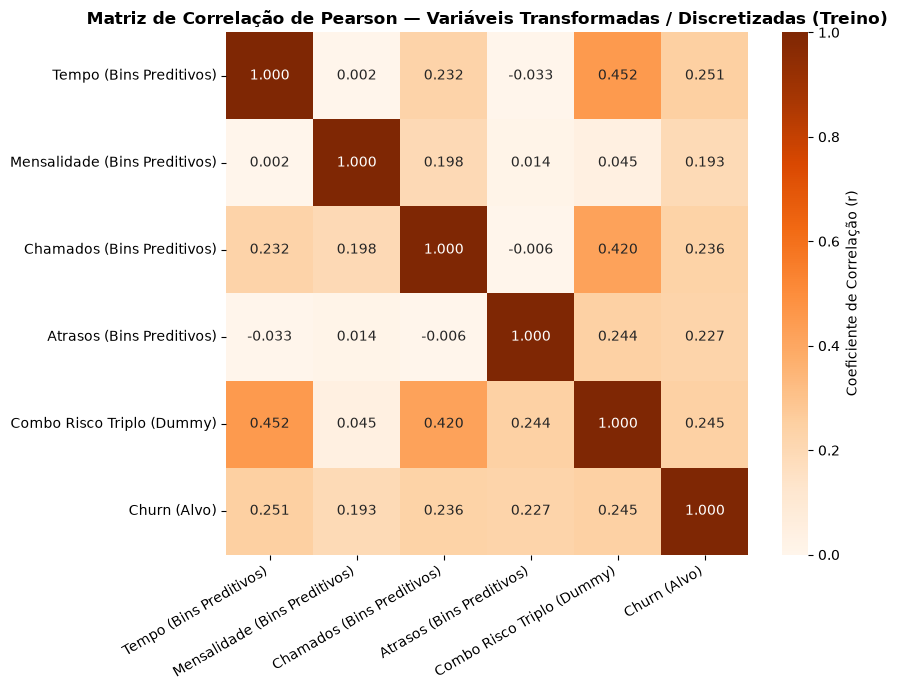

In [52]:
# Mesmo formato do slide "Matriz de Correlação de Pearson — Variáveis Transformadas / Discretizadas" (Aula 3)
correlacao_transf = transformadas.corr(method='pearson')

plt.figure(figsize=(9, 7))
sns.heatmap(correlacao_transf, annot=True, fmt='.3f', cmap='Oranges', vmin=0, vmax=1.0, square=True,
            cbar_kws={'label': 'Coeficiente de Correlação (r)'})
plt.title('Matriz de Correlação de Pearson — Variáveis Transformadas / Discretizadas (Treino)', fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

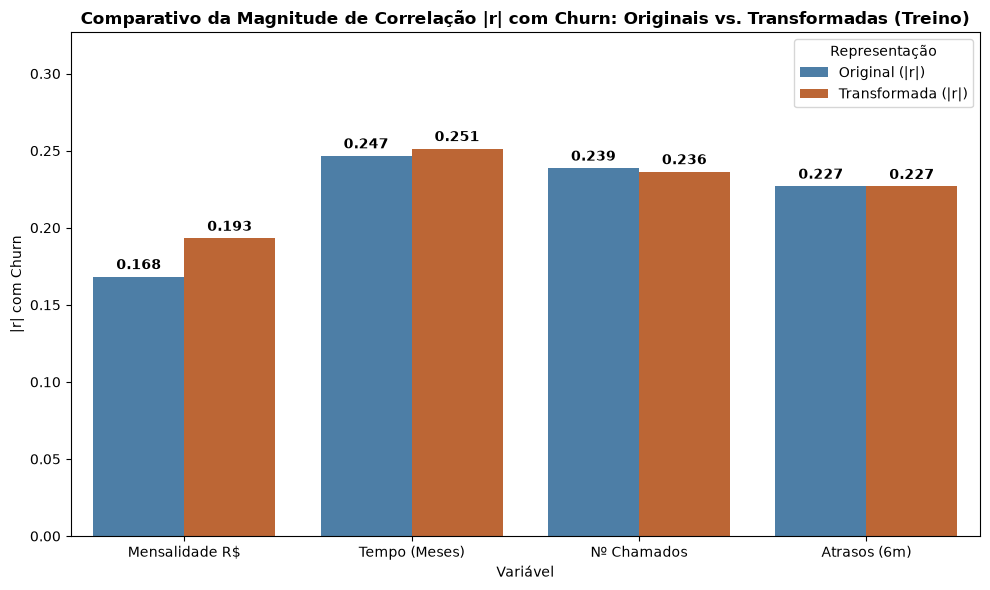

,Variável,Original (|r|),Transformada (|r|),Ganho relativo
0,Mensalidade R$,0.168,0.193,+14.8%
1,Tempo (Meses),0.247,0.251,+1.9%
2,Nº Chamados,0.239,0.236,-1.0%
3,Atrasos (6m),0.227,0.227,-0.1%


In [53]:
# Mesmo formato do slide "Comparativo de Magnitude |r| com Churn: Originais vs. Transformadas" (Aula 3)
comparativo = pd.DataFrame({
    'Variável': ['Mensalidade R$', 'Tempo (Meses)', 'Nº Chamados', 'Atrasos (6m)'],
    'Original (|r|)': [abs(correlacao.loc[v, 'Churn (Alvo)']) for v in ['Mensalidade R$', 'Tempo (Meses)', 'Nº Chamados', 'Atrasos (6m)']],
    'Transformada (|r|)': [abs(correlacao_transf.loc[f'{n} (Bins Preditivos)', 'Churn (Alvo)']) for n in ['Mensalidade', 'Tempo', 'Chamados', 'Atrasos']],
})
comparativo['Ganho relativo'] = (comparativo['Transformada (|r|)'] / comparativo['Original (|r|)'] - 1).map('{:+.1%}'.format)

dados_grafico = comparativo.melt(id_vars='Variável', value_vars=['Original (|r|)', 'Transformada (|r|)'],
                                 var_name='Representação', value_name='|r|')

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=dados_grafico, x='Variável', y='|r|', hue='Representação', palette=['#3e7fb5', '#d2601f'])
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.3f', padding=3, fontweight='bold')
ax.set_ylim(0, max(dados_grafico['|r|']) * 1.3)
ax.set_ylabel('|r| com Churn')
ax.set_title('Comparativo da Magnitude de Correlação |r| com Churn: Originais vs. Transformadas (Treino)', fontweight='bold')
plt.tight_layout()
plt.show()

display(comparativo.round(3))

In [54]:
# Conferência no teste: os bins e as taxas aprendidos no treino são aplicados no teste
# (se a correlação se mantém, a discretização não está apenas decorando o treino)
teste_tratado = pd.concat([X_teste, teste['churn']], axis=1)
for coluna, (cortes, taxa_por_faixa) in bins_preditivos.items():
    codificada = pd.cut(teste_tratado[coluna], bins=[-np.inf] + cortes + [np.inf]).map(taxa_por_faixa).astype(float)
    print(f"{coluna:18s} |r| treino = {abs(transformadas[f'{nomes_slide[coluna]} (Bins Preditivos)'].corr(treino_tratado['churn'])):.3f}"
          f" | |r| teste = {abs(codificada.corr(teste_tratado['churn'])):.3f}")

tempo_ativo_dias   |r| treino = 0.251 | |r| teste = 0.270
mensalidade_rs     |r| treino = 0.193 | |r| teste = 0.150
qtd_chamados       |r| treino = 0.236 | |r| teste = 0.303
atrasos_6m         |r| treino = 0.227 | |r| teste = 0.207


**Síntese:** a discretização por bins preditivos captura relações não lineares com o churn (por exemplo, o risco que cai rápido nos primeiros meses de contrato), o que pode aumentar a magnitude da correlação em relação à variável contínua original. O Combo Risco Triplo mostra o efeito de combinar várias faixas de risco em uma única regra.

**Conclusões da exploração:**

- **Tempo de cliente é o principal fator de proteção.** É a variável com maior correlação com o churn (r = −0,247) e maior KS (0,212). A taxa de churn é de cerca de 60% nos primeiros 6 meses e cai de forma contínua até menos de 10% para clientes com mais de 5 anos. O risco está concentrado nos clientes novos.

- **Chamados de suporte aumentam o risco.** Correlação de +0,239 e KS de 0,207. A taxa de churn sobe a cada chamado: cerca de 22% sem chamados, 29% com 1, 38% com 2, 46% com 3 e passa de 60% a partir de 5 chamados. Os grupos com 7 ou mais chamados têm poucos clientes, então suas taxas são menos confiáveis.

- **Atrasos indicam fragilidade financeira.** Correlação de +0,227. A média de atrasos de quem cancela (1,34) é maior que a de quem fica (0,89), e quem cancela se concentra em 1 a 3 atrasos.

- **Mensalidade tem a menor associação linear** (r = +0,168), mas a relação não é linear: no histograma e no violino, quem fica se concentra em mensalidades mais baixas (por volta de R$ 65) e quem cancela em mensalidades mais altas (por volta de R$ 90 a R$ 105). Por isso a discretização em bins preditivos aumentou a correlação dela de 0,168 para 0,193, o maior ganho entre as variáveis. Nas demais variáveis a correlação ficou praticamente estável.

- **Tipo de contrato é a categoria que mais separa as classes.** Contrato mensal tem 47,7% de churn, contra 23,9% no anual e 15,2% no bienal. O mapa de calor mostra que o contrato mensal tem alto churn em qualquer forma de pagamento (de 45% a 50,7%).

- **Forma de pagamento quase não diferencia o churn** (Pix 36,5%, Boleto 36,0%, Cartão 34,2%, todas próximas da média de 35,5%).

- **Fibra óptica e débito automático também separam as classes.** Clientes com fibra óptica cancelam mais (42,7% contra 26,1% sem fibra), e clientes com débito automático cancelam menos (27,0% contra 41,0% sem).

- **Combo Risco Triplo** (até 18 meses de cliente, 2 ou mais chamados e pelo menos 1 atraso): reúne 15,3% dos clientes do treino e tem 63,1% de churn, mais que o dobro dos clientes fora do combo (30,5%). Mostra que a combinação de fatores de risco identifica um grupo de risco muito alto.

- **Relação entre as variáveis:** as correlações entre os atributos são baixas (a maior é entre chamados e mensalidade, r = 0,199), então não há variáveis redundantes, e cada uma traz informação diferente para o modelo.

Esses resultados indicam que a base tratada tem sinal suficiente para os algoritmos supervisionados do próximo miniprojeto, com destaque para tempo de cliente, chamados, atrasos e tipo de contrato.


### Padronização das variáveis numéricas

O StandardScaler aprende a média e o desvio padrão somente no treino. O teste é apenas transformado com esses valores.

In [55]:
scaler = StandardScaler()
scaler.fit(X_treino[numericas])

X_treino[numericas] = scaler.transform(X_treino[numericas])
X_teste[numericas] = scaler.transform(X_teste[numericas])

display(pd.DataFrame({'média (treino)': scaler.mean_, 'desvio (treino)': scaler.scale_}, index=numericas).round(3))

,média (treino),desvio (treino)
tempo_ativo_dias,750.228,468.096
mensalidade_rs,83.336,18.268
qtd_chamados,1.706,1.426
atrasos_6m,1.052,0.949


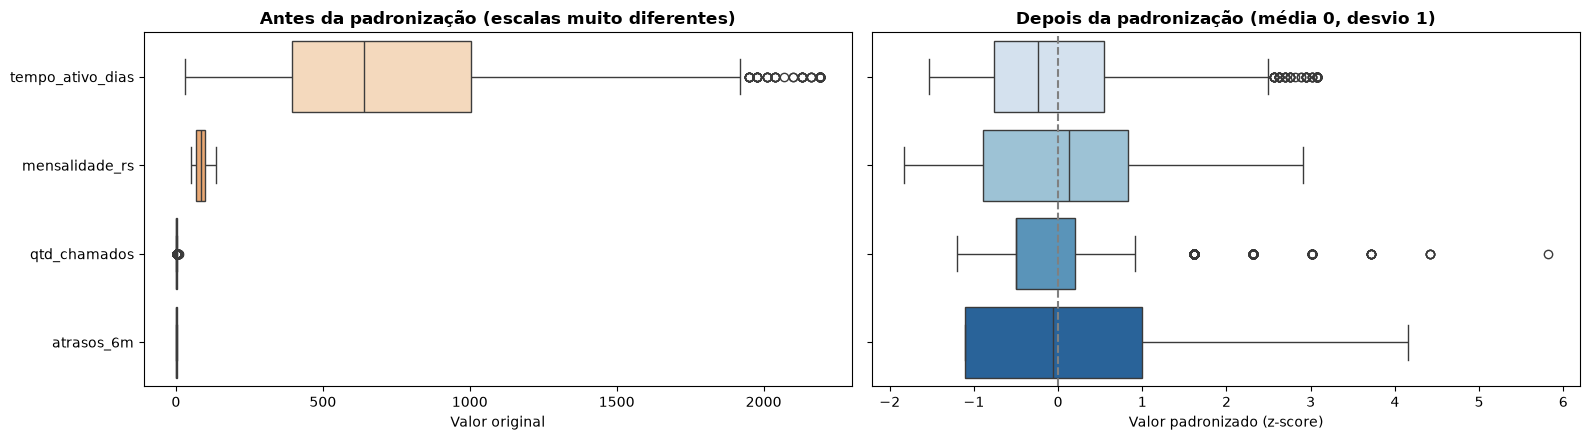

In [56]:
# Efeito do StandardScaler: antes cada variável tem uma escala; depois todas ficam com média 0 e desvio 1
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

sns.boxplot(ax=axes[0], data=treino_tratado[numericas], orient='h', palette='Oranges')
axes[0].set_title('Antes da padronização (escalas muito diferentes)', fontweight='bold')
axes[0].set_xlabel('Valor original')

sns.boxplot(ax=axes[1], data=X_treino[numericas], orient='h', palette='Blues')
axes[1].axvline(0, color='gray', linestyle='--')
axes[1].set_title('Depois da padronização (média 0, desvio 1)', fontweight='bold')
axes[1].set_xlabel('Valor padronizado (z-score)')
axes[1].set_yticklabels([])

plt.tight_layout()
plt.show()

### Contrato de dados

Regras de validação da Aula 2: problemas críticos bloqueiam o pipeline, os demais geram alerta.

In [57]:
def validar_contrato(base, nome):
    print(f"Contrato de dados - {nome}")
    # Validação de esquema (bloqueio)
    obrigatorias = ['id_cliente', 'data_corte'] + numericas + binarias_x + categoricas + ['churn']
    faltando = [c for c in obrigatorias if c not in base.columns]
    if faltando:
        raise Exception(f"BLOQUEIO: colunas obrigatórias ausentes {faltando}")
    # Validação do alvo (bloqueio)
    if base['churn'].isna().any() or not base['churn'].isin([0, 1]).all():
        raise Exception("BLOQUEIO: churn com valor faltante ou fora de {0, 1}")
    # Taxa de ausência da mensalidade (alerta acima de 20%)
    taxa = base['mensalidade_rs'].isna().mean()
    print(f"  {'ALERTA' if taxa > 0.20 else 'OK'}: mensalidade faltante = {taxa:.2%}")
    # Domínio categórico (alerta)
    for coluna, dominio in dominios.items():
        fora = (base[coluna].notna() & ~base[coluna].isin(dominio)).sum()
        print(f"  {'ALERTA' if fora else 'OK'}: valores fora do padrão em {coluna} = {fora}")
    # Duplicatas de chave (alerta)
    duplicados = base.duplicated(subset=['id_cliente', 'data_corte']).sum()
    print(f"  {'ALERTA' if duplicados else 'OK'}: chaves duplicadas = {duplicados}")

validar_contrato(treino, 'treino')
validar_contrato(teste, 'teste')

Contrato de dados - treino
  OK: mensalidade faltante = 2.61%
  OK: valores fora do padrão em tipo_contrato = 0
  OK: valores fora do padrão em forma_pagamento = 0
  OK: chaves duplicadas = 0
Contrato de dados - teste
  OK: mensalidade faltante = 2.74%
  OK: valores fora do padrão em tipo_contrato = 0
  OK: valores fora do padrão em forma_pagamento = 0
  OK: chaves duplicadas = 0


### Exportando a base transformada